# SFT 与 GRPO 训练实践

假设你已经有一个会回答问题的模型，现在希望它更稳定地解出数学题。你没有每道题的最佳推理过程，但能验证最终答案。例如，“6 箱苹果，每箱 7 个”可以有很多种解释，但最终数值应为 42。我们让模型尝试多个回答，按最终正确性评分，再提高相对较好回答的生成概率。

这份 notebook 用 **TRL + Transformers + PEFT + Accelerate + DeepSpeed + vLLM** 串起真实的训练路径。默认先运行不下载模型的 CPU 检查，再由你打开 CUDA 训练。它延续本仓库 [06_grpo_from_scratch.ipynb](06_grpo_from_scratch.ipynb) 的算法知识，把重点放到数据、采样、训练、评估与恢复的工程边界。

**读完并运行后，你可以：**

1. 用一个具体例子解释 reward 如何变成组内优势，以及 old policy 和 reference policy 的不同作用。
2. 算清每卡 micro batch、梯度累积、prompt 组数和回答复用次数，避免混淆采样量与训练量。
3. 用固定版本、固定数据与模型 revision 运行可选的 SFT warm start，再接 GRPO；解释单卡与训练/采样分离的多卡配置。
4. 用独立准确率、格式率、截断率、日志和 checkpoint 检查一次实验，并说明现有证据还不能证明什么。

### 阅读前的三个概念

**策略（policy）就是模型生成下一个 token 的概率分布。** token 是 tokenizer 切出的文本单位，不一定是一个汉字或一个单词。模型给定问题和已经生成的内容，为下一个 token 分配概率；连续选择 token，才得到一个完整回答。

**rollout 是采样得到的回答及其训练记录。** 在本任务中它是一段文本；在工具或机器人任务中，它还可能是一串动作与环境反馈。**后训练（post-training）**则是在已有语言能力上继续调整模型。本教程从 Instruct 模型起步，不从随机权重训练语言能力。

**监督微调（SFT）与这里的强化学习（RL）使用不同的监督信号。** SFT 告诉模型“照这个目标回答学习”；这里的 RL 让模型先生成，再用规则判断结果。最终答案能被验证，不等于每一步推理都有人工标签。示例属于 **RL with verifiable rewards（RLVR，可验证奖励的 RL）**，没有训练人类偏好 reward model。**GRPO 本身需要的是奖励信号，不要求每道题都预先提供正确答案。** 本例选择把生成的最终数值与标准数值 `gold` 比较来计算奖励，所以数据里保留了 gold；其他任务也可以使用测试结果、奖励模型评分或环境反馈。

### 如何运行与判断完成

先读第 1–4 节，确认环境、数据和评分口径；第 5 节用小张量检查更新方向；第 6–10 节把这些概念接到真实 Trainer；第 11–14 节负责启动、诊断和验证。默认 `RUN_SFT=False`、`RUN_TRAIN=False` 且 `SFT_MODEL=None`，因此顺序执行不会自动下载预训练权重或启动 GPU 训练，但仍需要安装 CPU 学习检查所用的依赖。

先修知识是 Python、PyTorch 的前向/反向传播，以及 next-token prediction。不了解分布式训练也可以从 `smoke` 开始。**完成一次教学实验的标准是：能追踪一批数据从题目到 reward、梯度、模型文件和独立评估的全过程，并能解释观察到的结果。** 仅看到 loss 下降还不够。

**证据边界：** CPU 数学检查与随机小模型集成检查可以离线运行；真实模型训练需要 Linux + NVIDIA CUDA GPU。多 GPU 配置是执行起点，不能当作已测过的集群容量或效果报告。第 14 节区分代码检查、训练链路检查和效果实验。


## 1. 运行环境

先用小模型确认链路，再增加模型和 GPU，能更快定位失败发生在哪一层。比如，`<answer>` 解析错误在 CPU 上就能暴露，不需要先启动八卡训练；只有采样、反向传播、保存和评估都接通后，才值得测量大模型的速度与效果。

### 1.1 两个运行档位

| 档位 | 模型与更新方式 | 训练 GPU | 采样 GPU | 用途 |
|---|---|---:|---:|---|
| `smoke` | Qwen2.5-0.5B-Instruct，LoRA | 1 | 使用训练卡的 Transformers generation | 20 个 optimizer steps，验证链路 |
| `scale` | Qwen2.5-7B-Instruct，全参数、ZeRO-3 | 4 | 另外 4 张，vLLM TP=4 | 展示训练/采样分离 |

LoRA 只更新附加的小矩阵，基座权重保持冻结；全参数训练会更新基座参数。ZeRO-3 把训练状态分布到多张卡，TP（tensor parallelism，张量并行）则把一次模型计算拆到多张采样卡。这些方式解决的问题不同，后面会逐一解释。

两个 profile 同时改变了模型大小、更新方式、长度和数据预算，所以它们不是严格控制变量的速度或效果对比。`smoke` 中的 smoke test 指短链路检查，不意味着 20 步必然提高准确率。

### 1.2 各个库负责什么

| 组件 | 在本教程中的职责 |
|---|---|
| Transformers | 加载 Qwen、tokenizer，执行模型前向和单卡生成 |
| TRL | 组织 SFT 的交叉熵训练，以及 GRPO 的采样、评分和策略损失 |
| PEFT | 在 smoke 档位插入并训练 LoRA adapter |
| Accelerate | 启动训练进程，管理设备和分布式执行 |
| DeepSpeed | 在 scale 档位分片参数、梯度与 optimizer 状态 |
| vLLM | 在专用 GPU 上批量生成回答，并接收 learner 的新权重 |

模型文件、tokenizer、chat template 和 Python API 都会影响实验。这里固定 **TRL 0.28.0** 及主要依赖版本，模型与数据也固定 revision。revision 是某个仓库版本的标识，避免同一个模型名在不同时间加载到不同文件；它并不保证跨硬件逐 bit 重现结果。固定版本的 API 说明见 [TRL 0.28.0 文档](https://huggingface.co/docs/trl/v0.28.0/en/grpo_trainer)。

### 1.3 创建独立环境

本配置与仓库其他 notebook 的依赖约束不同，因此使用单独环境。从仓库根目录运行：

```bash
uv venv --python 3.12 .venv-rl
uv pip install --python .venv-rl/bin/python -r notebooks/rl_training/requirements.txt
.venv-rl/bin/python -m ipykernel install --user --name practical-rl --display-name 'Python (practical RL)'
```

第一条创建解释器环境，第二条安装依赖，第三条把这个解释器注册为 Jupyter kernel。在 Jupyter 里选择 `Python (practical RL)`。如果终端安装成功，notebook 仍提示找不到包，先检查 kernel 是否选错，而不是重复修改代码。`scale` 还需要额外依赖，第 11 节给出安装与启动顺序。

下面的初始化单元设置 `PROFILE`、`RUN_TRAIN`、仓库根目录与输出位置。`RUN_SFT` 和 `RUN_TRAIN` 分别控制 SFT 与 GRPO 入口，默认都关闭，不跳过 reward、数学、mask 和批量规划检查。选择 SFT 后，GRPO 默认改用独立的 `output/sft-grpo/`，避免覆盖直接 GRPO 的实验。输出统一放在 `output/practical-rl/`，实验配置不同应选择不同运行目录。

### 1.4 显存预算与运行边界

`smoke` 建议从约 16–24 GB 显存开始测量，`scale` 以 8 × 80 GB 的节点作为规划起点。这些是估算，不是实测最低要求。训练时要容纳参数、梯度、optimizer 状态和前向激活；生成时还需要保存已生成上下文的 KV cache；reference 模型与保存全模型也可能造成额外峰值。因此，短回答能运行，不代表长度翻倍后仍能运行。

先记录峰值显存，再逐项调整 micro batch、长度与模型规模。增大梯度累积通常能增加有效 batch，而无需把所有样本的激活同时放进显存，但每次参数更新会花更多计算时间。不要在 CUDA 分布式训练里用 `device_map="auto"` 代替训练框架的参数分片。


In [1]:
from pathlib import Path
import os

PROFILE = 'smoke'
RUN_SFT = False  # 可选：先做单卡 LoRA SFT，默认不下载权重或训练。
RUN_TRAIN = False  # 可选：运行 GRPO；20 steps 验证链路，不保证准确率上升。
SFT_MODEL = None  # 或填已有的 output/practical-sft/smoke/merged 路径。
SFT_STEPS = 20
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
SFT_ARTIFACT_ROOT = ROOT / 'output/practical-sft'
ARTIFACT_ROOT = ROOT / ('output/sft-grpo' if RUN_SFT or SFT_MODEL else 'output/practical-rl')
print({'profile': PROFILE, 'run_sft': RUN_SFT, 'run_grpo': RUN_TRAIN, 'artifacts': str(ARTIFACT_ROOT)})


{'profile': 'smoke', 'run_sft': False, 'run_grpo': False, 'artifacts': '/Users/zhengzhang/personal/llm-coding-challenges/output/practical-rl'}


## 2. RL 训练流程

把一次循环想成“模型答题、规则判卷、模型调整答题概率”。与提前准备好所有目标回答的 SFT 不同，训练过程中模型会不断生成新的回答，后续看到的数据也随策略变化。这是 GRPO 的在线学习特征。

### 2.1 一批数据经过哪些阶段

| 阶段 | 输入 → 输出 | 必须守住的约束 |
|---|---|---|
| 数据准备 | GSM8K 问题 → chat prompt、私有 `gold` | `gold` 不进入 prompt；训练与评估问题不重合 |
| rollout（采样） | 近期策略、一个问题 → G 个 completion | 每组属于同一个问题；采样保留一定随机性 |
| verifier（评分器） | completion + `gold` → 0/1 reward | 明确解析最终答案，拒绝多个候选答案 |
| learner（更新器） | 回答 token、reward、旧概率 → 新策略参数 | prompt/padding 不直接计入策略损失；旧概率固定 |
| evaluation（评估） | 固定 held-out 问题 → 独立准确率 | 相同 prompt、长度上限和解码协议比较 before/after |

以苹果题为例，模型采样出 4 个回答，最终数值分别是 41、42、43、42。规则评分器给出 `[0, 1, 0, 1]`；learner 比较同题回答的相对好坏，让较好回答中的 token 获得提高概率的训练信号。下一轮用更新后的策略重新作答。组内比较的具体公式在第 5 节展开。

一次回答的训练记录除了文本，还需要 token ID、有效 token 的 mask、reward，以及对应 token 在旧策略下的 log probability。log probability 是概率的自然对数；很多 token 概率相乘会很小，用对数更容易计算。mask 是与 token 对齐的 0/1 标记，用来区分有效位置与应忽略的位置。单独保存“回答正确/错误”还不足以计算后面的策略概率比。

### 2.2 当前策略、old policy 与 reference policy

三者可能在训练刚开始时数值相同，但训练过程中的职责不同：

| 名称 | 什么时候变化 | 用来解决什么问题 |
|---|---|---|
| 当前策略 `pi_theta` | 每次 optimizer step 后变化 | 我们正在训练的模型 |
| old policy | 为本批 rollout 固定，下一批采样时刷新 | 比较当前概率与产生本批数据时的概率 |
| reference policy | 固定在 GRPO 起点，可为原 Instruct 或 SFT 后模型 | 用 KL（相对熵）正则约束相对起点的分布偏移 |

old policy 不一定意味着始终额外常驻一份完整模型：对于已经采样的 token，可以保存需要的旧 log probability。reference 则仍需对这些 token 提供参考概率；LoRA 和全参数模式实现 reference 的方式不同，第 8 节再说明。**概率比的分母来自 old policy，KL 比较对象是 reference，不能互换。**

### 2.3 on-policy 与回答复用

GRPO 通常归为与 PPO 类似的 on-policy 算法：持续用近期策略采样，再更新策略。本教程 `num_iterations=2`，同一批回答会经历两次参数更新。第一次更新后，回答仍来自更新前的策略，所以第二轮存在采样策略与当前策略的差异，需要使用固定的旧概率与受 clipping 约束的目标。它不是每次参数更新前都重新采样的严格情形，也不是从任意历史回答库无限复用数据。

梯度累积期间参数尚未更新，因此累积 K 个 micro step 本身不会造成同一种策略滞后。在线采样、梯度累积和 rollout 复用是三个不同概念，第 3 节将分别计数。原始算法背景见 [DeepSeekMath](https://arxiv.org/abs/2402.03300)。

### 2.4 训练与采样如何协作

在 `smoke` 中，同一训练进程用 Transformers 生成回答，再做反向传播。在 `scale` 中，learner 负责更新，独立 vLLM server 负责生成；生成新一批 rollout 前，训练侧把相应的新权重同步给 server。整个例子采用同步流程，没有让后台队列无限积累旧策略数据。

这里的 server 是 **TRL 的 `trl vllm-serve` 专用服务**，提供生成与权重更新所需的协作能力，普通 `vllm serve` 的 OpenAI 接口不能直接替代。第 11 节会区分 HTTP 请求和权重传输的通信路径。[TRL vLLM 集成说明](https://huggingface.co/docs/trl/v0.28.0/en/vllm_integration)


In [2]:
import argparse
from dataclasses import asdict, dataclass, replace
from decimal import Decimal, InvalidOperation
import hashlib
import importlib.metadata
import json
import math
import random
import re
import sys
import time
from pathlib import Path

LIBRARY_VERSIONS = {
    'trl': '0.28.0', 'transformers': '4.57.3',
    'accelerate': '1.12.0', 'datasets': '4.4.1', 'peft': '0.18.0',
}
DATA_REVISION = '740312add88f781978c0658806c59bc2815b9866'

@dataclass(frozen=True)
class Recipe:
    profile: str
    model: str
    model_revision: str | None
    output_dir: str
    expected_world_size: int
    micro_batch: int
    grad_accum: int
    group_size: int
    max_steps: int
    train_limit: int
    validation_limit: int
    max_prompt_tokens: int
    max_completion_tokens: int
    lora: bool
    use_vllm: bool
    seed: int = 42
    beta: float = 0.02
    num_iterations: int = 2
    learning_rate: float = 5e-6
    vllm_url: str = 'http://127.0.0.1:8000'
    deepspeed: str | None = None
    warm_start: dict | None = None

def make_recipe(profile, output_root='output/practical-rl'):
    shared = dict(profile=profile, output_dir=str(Path(output_root) / profile))
    if profile == 'smoke':
        return Recipe(**shared,
            model='Qwen/Qwen2.5-0.5B-Instruct',
            model_revision='7ae557604adf67be50417f59c2c2f167def9a775',
            expected_world_size=1, micro_batch=2, grad_accum=4, group_size=4,
            max_steps=20, train_limit=128, validation_limit=32,
            max_prompt_tokens=512, max_completion_tokens=256,
            lora=True, use_vllm=False)
    if profile == 'scale':
        ds = Path(__file__).resolve().with_name('deepspeed_zero3.json') if '__file__' in globals() else ROOT / 'notebooks/rl_training/deepspeed_zero3.json'
        return Recipe(**shared,
            model='Qwen/Qwen2.5-7B-Instruct',
            model_revision='a09a35458c702b33eeacc393d103063234e8bc28',
            expected_world_size=4, micro_batch=2, grad_accum=16, group_size=8,
            max_steps=500, train_limit=6500, validation_limit=256,
            max_prompt_tokens=1024, max_completion_tokens=1024,
            lora=False, use_vllm=True, learning_rate=1e-6,
            deepspeed=str(ds))
    raise ValueError(f'Unknown profile: {profile}')

def batch_plan(recipe, world_size=None):
    w = recipe.expected_world_size if world_size is None else world_size
    n = recipe.micro_batch * w * recipe.grad_accum
    if recipe.group_size < 2 or n % recipe.group_size:
        raise ValueError('Generation batch 必须包含完整的 G 个回答组，且 G >= 2')
    return {
        'world_size': w, 'completions_per_optimizer_step': n,
        'completions_per_generation': n,
        'unique_prompts_per_generation': n // recipe.group_size,
        'optimizer_steps_per_generation': recipe.num_iterations,
        'completion_token_upper_bound_per_generation': n * recipe.max_completion_tokens,
    }


## 3. 批大小与采样分组

本节讨论 GRPO 的批量计数；SFT 的每条示范计数见第 7 节。本教程把 `steps_per_generation` 固定为 gradient accumulation steps（记为 K），每 GPU 的 micro batch 记为 b，训练 GPU 数记为 W，每个 prompt 的回答数记为 G。

| 参数 | 是干什么的 | 直观理解 |
|---|---|---|
| **b：每 GPU 的 micro batch size** | 每张 GPU 在一次前向、反向计算中处理多少条训练样本 | 一张卡一小批处理多少条 |
| **W：训练 GPU 数** | 在本教程的数据并行设置下，多少张 GPU 同时处理不同样本 | 有多少张卡一起干活 |
| **K：gradient accumulation steps** | 连续计算 K 个 micro batch，累积梯度后，再更新一次模型参数 | 攒多少小批，才更新一次 |
| **G：每个 prompt 的回答数** | 对同一道问题采样 G 个回答，比较它们的奖励，得到各回答的相对好坏 | 一道题让模型尝试多少次 |
| **`steps_per_generation`** | 控制一次生成批量的大小，使这批回答在一轮训练中够用多少个 micro step；本教程设为 K | 一次准备多少小批的训练材料 |

### 3.1 样本与回答组

这里的 **b 按“prompt + 一个回答”这样的样本计数**。例如，同一道数学题生成 4 个回答，就得到 4 条训练样本。它们的问题相同，但回答、奖励和训练信号可以不同。因此，b=2 表示一张 GPU 一次处理 2 条这样的样本，并不表示处理 2 道不同的题，也不表示每道题再额外生成 G 个回答。

> **注意不同框架的 batch size 计数口径。** 每个回答作为一条训练样本是常见做法，但名为 batch size 的配置可能数的是 prompt、回答或 token。本教程使用的 [TRL GRPO](https://huggingface.co/docs/trl/v0.28.0/grpo_trainer) 中，`per_device_train_batch_size` 按回答样本计数：b=8 就是每张卡每个 micro step 处理 8 条回答样本，不需要再乘 G。[verl](https://github.com/verl-project/verl/blob/main/docs/perf/best_practices.rst) 的 `data.train_batch_size` 则按 prompt 数计数：设为 8、`rollout.n=4`，一次 rollout 会产生 8 × 4 = 32 条回答样本。这两个参数处在不同的批量层级，不能直接比较数值；阅读其他框架或教程时，要先确认计数单位，以及它指的是全局批量还是每卡 micro batch。

G 个回答组成一个比较组，用来计算组内相对优势；b 决定训练时每张卡一次处理几条样本。这两个边界不必重合。**即使 b 小于 G，也可以把同一组回答分到多个 micro batch，或者不同 GPU 上训练**，只要计算优势时已经收齐这道题的 G 个奖励。

### 3.2 生成批量与参数更新

一个 **micro step** 是各张训练 GPU 各自处理一个 micro batch，完成前向和反向计算。每张卡处理 b 条，W 张卡合计处理 **b × W 条样本**。反向计算得到梯度，但此时可以先不更新参数。连续累积 K 个 micro step 后，优化器才执行一次参数更新，这才是一个 **optimizer step**。所以，一个 optimizer step 消费 **b × W × K 个 completion**，不是 K 次参数更新。

`steps_per_generation` 控制每次准备多少训练材料：一次 generation 的全局回答数为 **b × W × steps_per_generation**。K 控制多久更新一次参数，二者本来是独立设置。本教程把它们设成相同值，于是 **一次 generation 产生的回答，刚好够完成一次 optimizer step 所需的 K 个 micro step**。这里的 generation 指一批回答的采样过程，不是生成一个 token，也不要求所有回答在一次底层推理调用中同时生成。

每道题占 G 个回答名额，所以一次 generation 中的 prompt 组数为 **b × W × K / G**。这要求 b × W × K 能被 G 整除，否则无法组成完整的回答组。这里按每组对应一道题来计数；如果数据集中有重复题目，不保证题目文本都不同。

### 3.3 smoke 的完整计数

`smoke` 使用 b=2、W=1、K=4、G=4，并设置 `steps_per_generation=4`。一次采样需要 2 × 1 × 4 = **8 个回答**，也就是 **2 道题，每道题 4 个回答**。先根据每道题的 4 个奖励计算相对优势，再把这 8 条样本分成 4 个 micro batch：

| 阶段 | 处理的材料 | 参数是否更新 |
|---|---|---|
| 采样 | 题目 A 的 4 个回答、题目 B 的 4 个回答 | 否 |
| 打分 | 分别在 A、B 的组内计算优势 | 否 |
| micro step 1–3 | 每步 2 条样本，共 6 条，持续累积梯度 | 否 |
| micro step 4 | 剩余 2 条样本，完成本轮 8 条的计算 | 累积结束，更新一次 |
| 第二轮 | 再分 4 个 micro step 使用同一批 8 条样本 | 再更新一次 |

上面的流程只描述这批回答的一轮训练。**`num_iterations=2` 表示把同一批 rollout，也就是已经生成的回答及其奖励、采样时的 log probability 等记录，用于两轮训练**。在本教程的批量设置下，第一轮经过 4 个 micro step 更新一次参数；第二轮再处理同样的 8 条样本，经过另外 4 个 micro step，再更新一次参数，然后才生成下一批回答。第二轮可以改变样本顺序，但不会因此得到新回答。

因此，这个采样周期一共执行 **8 个 micro step、2 个 optimizer step**，处理了 **16 次样本**，但只有 **8 个新采样的回答、2 个 prompt 组**。和 `num_iterations=1` 相比，在相同的 optimizer step 预算下，新采样批次约减半；复用提高了每批数据的利用次数，并没有带来双倍独立数据。这里说的新 prompt，是本次重新采样所用的题目，不保证训练历史中从未出现过。

这也解释了它与 on-policy 的关系：梯度累积期间参数不变，所以累积 K 次本身不会让策略变旧；第一轮参数更新后，第二轮仍使用旧策略生成的回答，就存在采样策略与当前策略的差异。GRPO 用当前策略与采样时旧策略的概率比值及 clipping 来处理和约束这种更新。参见 [TRL 的 GRPO 目标与 num_iterations 说明](https://huggingface.co/docs/trl/v0.28.0/grpo_trainer)。

### 3.4 调参时固定了什么预算

两个 profile 的计数如下，均设置 `num_iterations=2`：

| profile | b | W | K | G | 每次生成的回答数 | 每次生成的 prompt 组数 | 复用两轮的样本处理次数 |
|---|---:|---:|---:|---:|---:|---:|---:|
| smoke | 2 | 1 | 4 | 4 | 8 | 2 | 16 |
| scale | 2 | 4 | 16 | 8 | 128 | 16 | 256 |

增大某个参数时，先说明哪些量保持不变。例如，固定 b、W、K，增大 G 会让每题回答变多、题目组变少，回答总数不变；固定题目组数再增大 G，则回答总数与成本都会增加。增加 K 而保持 b、W 不变，会扩大每次更新的有效 batch；本教程还令 `steps_per_generation=K`，所以生成批量也随之扩大。

`max_steps` 数的是 optimizer step。smoke 从头完成 20 步时，会处理 20 × 8 = 160 次训练样本；因为每批复用两次，约对应 80 个新采样回答、20 个 prompt 组的采样，尚未计入额外评估。这里的组数不是 20 道保证不重复的新题，不能拿数据集有 128 道训练题就假定它们都已经用于更新。

`scale`：2 × 4 × 16 = 128 个 completion，来自 16 道题，每题 8 个回答。1024 的回答上限使它最多包含 131,072 个 response token，但实际 token 数取决于停止位置。不要拿这个上限冒充吞吐量。

<details><summary>练习：G 从 8 改到 16，会发生什么？</summary>
completion batch 不变时，不同 prompt 数从 16 减到 8。同题比较更丰富，但一个 batch 的问题覆盖变少。G 不是无代价的提升开关。
</details>


In [3]:
for name in ['smoke', 'scale']:
    print(name, batch_plan(make_recipe(name, ARTIFACT_ROOT)))
try:
    batch_plan(replace(make_recipe('smoke'), group_size=3))
except ValueError as exc:
    print('非法 batch 被拦截:', exc)


smoke {'world_size': 1, 'completions_per_optimizer_step': 8, 'completions_per_generation': 8, 'unique_prompts_per_generation': 2, 'optimizer_steps_per_generation': 2, 'completion_token_upper_bound_per_generation': 2048}
scale {'world_size': 4, 'completions_per_optimizer_step': 128, 'completions_per_generation': 128, 'unique_prompts_per_generation': 16, 'optimizer_steps_per_generation': 2, 'completion_token_upper_bound_per_generation': 131072}
非法 batch 被拦截: Generation batch 必须包含完整的 G 个回答组，且 G >= 2


## 4. 奖励函数

奖励函数回答的是：**模型已经生成了这个回答，我们应该给它多少分？** 本教程使用一个确定性的规则评分器，也叫 verifier：它检查输出格式，再把最终数值与标准答案比较，不需要另一个模型来打分。同一份输出和 gold 总会得到相同的奖励。

**需要 gold 是本例评分器的选择，不是 GRPO 的通用要求。** GRPO 让模型自己生成回答，再接收每个回答的标量奖励。算法需要可用的评价信号，但没有规定这个信号必须来自与标准答案的比较：

| 任务与奖励机制 | 是否需要每题的标准答案 |
|---|---|
| 本例 GSM8K：把最终数值与 gold 比较 | 需要标准数值，不需要标准推理过程 |
| 代码任务：根据测试通过率评分 | 不需要标准代码，但需要测试用例或其他验证规则 |
| 开放式回答：由奖励模型评分 | GRPO 训练时不一定需要逐题标准答案，但需要可用的奖励模型 |
| 环境任务：根据游戏得分或任务完成情况评分 | 不一定需要，评价信号由环境提供 |

奖励模型本身如何训练、测试规则是否充分，是奖励机制的另外一层问题；“不需要标准答案”不表示没有监督来源，也不表示评分一定可靠。若既没有标准答案，也没有测试、奖励模型或环境反馈，GRPO 无法仅靠组内比较判断哪个回答更好。

在本例中，问题交给模型生成回答，gold 只在生成之后交给评分器：

$$
y_i\sim\pi_{\mathrm{old}}(\cdot\mid x),\qquad
R(x,y_i)=\mathbf 1[\text{格式有效，且最终数值等于 gold}].
$$

因此，本例 GRPO 不需要照着一份正确解答逐 token 学习，也不使用数据集中的标准推理过程作为策略的监督目标；最终数值 gold 用于评分。可选的 SFT 阶段则会使用原始解答构造示范回答，两条路径在第 6–7 节分别说明。

### 4.1 模型输出什么，评分器检查什么

输出可以有推理文字，但必须以唯一的 `<answer>数值</answer>` 结尾。例如，标准答案为 42 时，下面的输出可以得分：

```text
There are 6 boxes with 7 apples each, so 6 × 7 = 42.
<answer>42</answer>
```

`parse_completion` 负责从模型输出中提取最终数值。它要求恰好出现一个 `<answer>` 和一个 `</answer>`，标签内部只能是允许的数值，结束标签后只能有空白。前面的推理文字可以省略。因此，只有 `<answer>42</answer>` 也有效，而输出两个候选答案、缺少标签或在标签后继续解释都会被拒绝。这样，评分器不必猜测模型最终选择了哪个数。

本实现接受带正负号的整数、小数，以及规范的千位分隔符，例如 `-5`、`42.0`、`1,000`。它不接受表达式、分数、科学计数法或特殊值，例如 `6*7`、`84/2`、`4.2e1`、`NaN`。这些是本教程的输出协议，不代表它们在数学上没有意义。代码还拒绝超过 100,000 个字符的输出，这是解析器的保护条件，与生成时的 token 上限是两回事。

### 4.2 标准答案如何提取，为什么用 Decimal

GSM8K 的原始 `answer` 字段包含解题过程，最终答案放在 `####` 后面。例如：

```text
There are 6 * 7 = 42 apples.
#### 42
```

`parse_gold` 只取分隔符后面的数值，不把数据集中的解题过程当作模型输出。它要求恰好一个 `####`，数值可解析且为整数；不符合要求就报错，以便暴露数据问题。**标准答案异常不能悄悄变成模型的 0 分样本**，否则模型会因评分数据有问题而受到错误训练信号。

比较前会去掉规范的千位逗号，再转为 `Decimal`。因此，`42`、`42.0`、`42.00` 的数值相同，`1,000` 与 `1000` 也相同。我们比较的是数值，不是字符串拼写。`Decimal` 还避免引入二进制浮点表示的舍入误差，但这里并没有设置“差不多就算对”的容差：`42.0001` 与 42 不相等。

### 4.3 奖励是格式与正确性的联合判断

**只有格式有效且答案正确才给 1 分，否则 0 分。** 逻辑可以写成：

1. 从 completion 提取唯一的最终数值；提取失败就返回 0.0。
2. 将数值与 gold 转成 Decimal 后比较。
3. 相等返回 1.0，不相等返回 0.0。

下面都假设 gold 为 42：

| 模型输出 | reward | 原因 |
|---|---:|---|
| `We calculate 40+2. <answer>42</answer>` | 1 | 格式有效，数值正确 |
| `<answer>42.0</answer>` | 1 | 数值与 42 相等 |
| `<answer>41</answer>` | 0 | 格式有效，但答案错误 |
| `The answer is 42.` | 0 | 数值虽对，但没有约定的最终答案标签 |
| `<answer>41</answer><answer>42</answer>` | 0 | 出现多个答案，不能靠枚举候选值得分 |
| `<answer>42</answer> or 43` | 0 | 结束标签后还有非空白文字 |
| `<answer>6*7</answer>` | 0 | 标签内部是表达式，不是允许的数值 |
| `<answer>42.0001</answer>` | 0 | 可解析，但与 gold 不相等 |

没有独立的格式 bonus。例如，错误答案从 `41` 改成 `<answer>41</answer>`，reward 仍然是 0。这样可以避免模型只学会套标签，就在没有提高答案正确率的情况下抬高奖励。这里的取舍是：格式改善本身也不会得到部分分数。

每个回答单独得到一个标量奖励。同一道题生成 G 个回答，就得到 G 个奖励；评分时，每个回答都必须配上这道题的同一个 gold，并保持一一对应。**评分器先判断每个回答是否正确，GRPO 再比较这 G 个奖励，计算相对优势**。下面一节才会把奖励变成用于策略更新的信号。

### 4.4 稀疏奖励为什么会让起步更难

模型要同时满足格式和正确性，才会得到非零奖励。如果训练初期还不会按协议输出，即使正文里已经算出正确数值，也可能整组得到 `[0, 0, 0, 0]`。在本教程的组内优势计算下，可以区分三种情况：

| 同题 4 个回答的奖励 | GRPO 能获得的相对信号 |
|---|---|
| `[0, 0, 0, 0]` | 全都一样差，无法区分应该提高哪个回答的概率 |
| `[0, 1, 0, 0]` | 有好坏差异，可以提高正确回答的概率，降低错误回答的概率 |
| `[1, 1, 1, 1]` | 全都一样好，这个二值评分器也无法进一步区分优劣 |

全组奖励相同时，各回答的组内相对优势为 0，因此没有 reward 驱动的策略梯度信号；本教程 beta>0，KL 正则项仍可能产生更新，不能据此说整个训练梯度一定为 0。

如果很少出现可区分的奖励组，可以先用少量训练集示例做 SFT，让模型学会 `<answer>…</answer>` 的输出协议，再开展 RL。第 7 节实现了可选 SFT：它不仅教格式，也利用训练集现有解答提供示范；默认仍不自动执行。排查时应同时观察格式有效率和最终正确率：前者低说明输出协议可能是障碍，前者高而后者低则说明仅学会格式还不够。也应抽查被拒绝的输出，确认规则没有误伤本来想接受的答案形式。

### 4.5 奖励的边界与 gold 的隔离

这个 verifier 只检查本任务的最终数值，**不验证推理过程**。如果前面写了错误推导，但最后恰好输出正确数值，它仍然给 1 分；如果推理大部分正确，但最终答案错误，它仍然给 0 分。它也不奖励解释质量、简洁性或可读性。因此，“reward=1”应理解为“通过了这里定义的最终答案检查”，不能直接等同于“推理可靠”。

它不能直接用于代数等价、证明题或通用聊天。代数式可能需要符号等价检查，证明题需要检查论证，开放式回答需要另外定义质量标准。更换任务时，要重新设计 verifier；只更换数据集，沿用这个数值比较器是不够的。

评分器里的 `gold` 是私有元数据，必须与策略输入隔离。数据记录可以同时保存 `prompt` 和 `gold`，但在 GRPO 采样与生成评估时，模型只应看到 system 指令和题目；`gold` 留给模型生成之后的评分过程：

| 数据 | 进入哪个阶段 | 是否交给策略模型 |
|---|---|---|
| 题目与输出格式要求 | 构造 prompt，生成回答 | 是 |
| 标准答案 gold | 回答生成后，交给 verifier | 否 |
| 生成回答与 gold 的比较结果 | 作为 reward，交给 GRPO 更新 | 以奖励信号参与更新，不作为题目输入 |

后面的 `make_prompt` 只接收 question，`prepare_data` 将 gold 保存在独立字段中。如果把原始 `answer` 字段中的解题过程或最终答案拼进 prompt，模型可能靠复制就拿到高分，这种答案泄漏会让训练和评估结果失去原本的意义。


### 4.6 如何阅读下面的实现

`completion_text` 先把字符串或单条 assistant 消息统一成文本；`parse_completion` 检查并提取模型最终数值；`parse_gold` 清洗数据集标准答案；`correctness_reward` 对齐回答和 gold，返回浮点分数列表。这个职责拆分让解析问题和模型能力问题可以分别排查。

评分过程不需要可微：正则和 Decimal 比较不会把梯度传回生成文本。GRPO 后续使用这些固定分数构造优势，再对模型生成已采样 token 的 log probability 求导。因此，不需要为了做 RL 把 verifier 改写成一个神经网络。

`reward_self_test` 同时检查字符串和 chat completion 两种输入形式，包括正确数值、错误数值、重复标签、尾部附加文字、非规范数字等反例。它检验的是这个输出协议的行为，不能覆盖所有自然语言答案。扩展任务或修改 parser 时，应先明确哪些新形式应接受，再补充对应反例，避免不知不觉改变奖励定义。


In [4]:
NUMBER = r'[-+]?(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?'
FINAL_ANSWER = re.compile(r'<answer>\s*(' + NUMBER + r')\s*</answer>\s*\Z')
SYSTEM_PROMPT = (
    'Solve the math problem. You may explain your reasoning. '
    'End with exactly one <answer>NUMBER</answer> tag. '
    'Do not write anything after that tag.'
)

def completion_text(completion):
    if isinstance(completion, str):
        return completion
    if isinstance(completion, list) and len(completion) == 1:
        message = completion[0]
        if isinstance(message, dict) and message.get('role') == 'assistant':
            return message.get('content', '')
    return ''

def parse_completion(text):
    if not isinstance(text, str) or len(text) > 100_000:
        return None
    if text.count('<answer>') != 1 or text.count('</answer>') != 1:
        return None
    match = FINAL_ANSWER.search(text)
    if match is None:
        return None
    try:
        return Decimal(match.group(1).replace(',', ''))
    except InvalidOperation:
        return None

def parse_gold(answer):
    if answer.count('####') != 1:
        raise ValueError('GSM8K answer missing a unique #### delimiter')
    value = answer.split('####')[1].strip()
    if not re.fullmatch(NUMBER, value):
        raise ValueError(f'Unexpected gold format: {value!r}')
    number = Decimal(value.replace(',', ''))
    if number != number.to_integral_value():
        raise ValueError('This recipe expects GSM8K integer gold answers')
    return str(number)

def correctness_reward(completions, gold, **kwargs):
    if len(completions) != len(gold):
        raise ValueError('completions/gold must align one-to-one')
    return [
        float(parse_completion(completion_text(c)) == Decimal(g))
        for c, g in zip(completions, gold)
    ]

def reward_self_test():
    cases = [
        ('We calculate 40+2. <answer>42</answer>', '42', 1.),
        ('<answer>42.0</answer>', '42', 1.),
        ('<answer>1,000</answer>', '1000', 1.),
        ('<answer>-5</answer>', '-5', 1.),
        ('<answer>41</answer>', '42', 0.),
        ('The answer is 42.', '42', 0.),
        ('<answer>0</answer><answer>42</answer>', '42', 0.),
        ('<answer>42</answer> or 43', '42', 0.),
        ('<answer>1,2</answer>', '12', 0.),
        ('<answer>NaN</answer>', '42', 0.),
        ('<answer>Infinity</answer>', '42', 0.),
        ('<answer>42', '42', 0.),
        ('<answer>4e1</answer>', '40', 0.),
    ]
    for text, gold, expected in cases:
        assert correctness_reward([text], [gold]) == [expected], text
        chat = [{'role': 'assistant', 'content': text}]
        assert correctness_reward([chat], [gold]) == [expected]
    assert parse_gold('Some reasoning. #### 1,000') == '1000'
    print(f'{len(cases) * 2 + 1} reward checks passed')


In [5]:
reward_self_test()


27 reward checks passed


## 5. GRPO 目标函数

奖励只是“这个回答得了几分”，目标函数还必须决定“哪些 token 的概率该提高、提高多少，以及什么时候停止继续鼓励”。本节从同一道题的 4 个回答开始，把这几步接起来。先理解每一项的作用，再看合在一起的公式。

### 5.1 从绝对分数到相对优势

假设 4 个回答的 reward 是 `[0, 1, 0, 1]`。平均分为 0.5，得 1 分的回答比同组平均好，得 0 分的回答比平均差。这个相对差距叫 **优势（advantage）**。GRPO 用组内比较建立基线，不另训练一个 value/critic 网络来预测基线。

第 i 个回答的 reward 记为 $r_i$，组内均值记为 $\mu$，样本标准差记为 $s$。本教程采用 `scale_rewards="group"`，优势为：

$$A_i=\frac{r_i-\mu}{s+10^{-4}}.$$

对 `[0, 1, 0, 1]`，样本标准差约为 0.577，所以优势约为 `[-0.866, +0.866, -0.866, +0.866]`。正号表示鼓励该回答，负号表示抑制该回答；reward 本身仍然只有 0 和 1。分母中的小常数避免标准差为 0 时除零，但不会为全同分组凭空制造差异。

这里先减同题均值，再除以同题标准差。同一回答的有效 response token 共享这个优势，因此这是回答级结果对 token 的共同反馈，并不意味着每一步推理都被单独验证。标准差归一化也会改变不同题目的信号尺度，不能把它当成无关紧要的数值技巧。

### 5.2 从期望奖励到策略损失

训练希望模型更常生成高奖励回答。例如，对“6 箱苹果，每箱 7 个”，提高正确回答的概率，才能提高反复采样时的平均得分。先固定问题 $x$，把完整回答记为 $y$，其生成概率记为 $\pi_\theta(y\mid x)$，评分器给出的奖励记为 $R(y)$。最直接的目标是最大化期望奖励：

$$
J(\theta)=\mathbb E_{y\sim\pi_\theta(\cdot\mid x)}[R(y)]
=\sum_y\pi_\theta(y\mid x)R(y).
$$

**log 来自对期望奖励求梯度。** 这里评分器固定，奖励不直接对模型参数 $\theta$ 求导；模型通过改变回答的生成概率来改变平均奖励。利用 $\nabla_\theta\log\pi_\theta=(\nabla_\theta\pi_\theta)/\pi_\theta$，有：

$$
\begin{aligned}
\nabla_\theta J(\theta)
&=\sum_y R(y)\nabla_\theta\pi_\theta(y\mid x)\\
&=\sum_y\pi_\theta(y\mid x)R(y)\nabla_\theta\log\pi_\theta(y\mid x)\\
&=\mathbb E_{y\sim\pi_\theta}[R(y)\nabla_\theta\log\pi_\theta(y\mid x)].
\end{aligned}
$$

这个形式让我们可以用采样到的回答估计梯度，无须遍历所有可能的回答，也无须对离散采样或答案评分器反向传播。奖励告诉我们更新力度，log probability 提供可微的更新方向。

**基准项的期望贡献为 0，依赖一个条件。** 基准 $b(x)$ 可以随问题变化，但不能依赖当前采样回答 $y$；在策略损失中把它作为固定数值，不对它反向传播。令 $A(y)=R(y)-b(x)$，基准项对策略梯度的期望贡献为：

$$
\begin{aligned}
\mathbb E_{y\sim\pi_\theta}[b(x)\nabla_\theta\log\pi_\theta(y\mid x)]
&=\sum_y\pi_\theta(y\mid x)b(x)
\frac{\nabla_\theta\pi_\theta(y\mid x)}{\pi_\theta(y\mid x)}\\
&=b(x)\nabla_\theta\sum_y\pi_\theta(y\mid x)\\
&=b(x)\nabla_\theta 1=0.
\end{aligned}
$$

所有回答的概率之和始终为 1，所以提高一些回答的概率时，其他回答的概率必须相应降低；同一个基准对这些变化的贡献在期望中抵消。例如只有两个回答，概率分别为 $\theta$ 和 $1-\theta$，基准项贡献为 $b\cdot1+b\cdot(-1)=0$。这里为 0 的是**所有可能回答上取期望后的贡献**，不是单个回答的 $b(x)\nabla_\theta\log\pi_\theta(y\mid x)$；有限采样时通常不会精确抵消。

因此，对满足上述条件的基准：

$$
\mathbb E[(R-b)\nabla_\theta\log\pi_\theta]
=\mathbb E[R\nabla_\theta\log\pi_\theta].
$$

平均更新方向保持不变，合适的基准通常还能降低梯度估计的方差。仅仅对基准执行 `detach` 并不足以保证这个结论：`detach` 控制反向传播，基准与当前回答是否存在统计依赖是另一个问题。

**GRPO 的组均值包含当前回答，所以不能直接套用上式。** 先只看减均值，不除以标准差。固定同一道题，假设从同一当前策略独立采样 $G>1$ 个回答，奖励只由各自回答决定；暂不考虑 clipping、KL 或旧 rollout 的复用。令：

$$
\bar R=\frac1G\sum_{j=1}^G R_j,\qquad
s_i=\nabla_\theta\log\pi_\theta(y_i\mid x),\qquad
g=\mathbb E[R_i s_i]=\nabla_\theta J(\theta).
$$

这里 $s_i$ 是第 i 个回答的 log probability 对模型参数的梯度向量，与 5.1 节的奖励标准差 $s$ 不同。对 $j\ne i$，其他回答的奖励 $R_j$ 与 $s_i$ 独立，而且 $\mathbb E[s_i]=\nabla_\theta\sum_y\pi_\theta(y\mid x)=0$，所以：

$$
\begin{aligned}
\mathbb E[\bar R\,s_i]
&=\frac1G\mathbb E[R_i s_i]
+\frac1G\sum_{j\ne i}\mathbb E[R_j]\mathbb E[s_i]
=\frac1Gg,\\
\mathbb E[(R_i-\bar R)s_i]
&=\left(1-\frac1G\right)g.
\end{aligned}
$$

所以在这些假设下，**只减组均值会保持期望梯度方向，但把幅度缩小到原来的 $(G-1)/G$**；G=4 时为 $3/4$。对组内各回答的梯度取平均，期望也相同。这不是“基准项贡献为 0”，而是基准项留下了一个可计算的缩放。

**排除当前回答的基准可以恢复零期望结论。** 用其他 $G-1$ 个回答的平均奖励作为基准，称为 leave-one-out baseline：

$$
b_{-i}=\frac1{G-1}\sum_{j\ne i}R_j,\qquad
\mathbb E[b_{-i}s_i]=0,\qquad
\mathbb E[(R_i-b_{-i})s_i]=g.
$$

在上述独立采样条件下，$b_{-i}$ 与当前回答独立。两种中心化还有逐样本的关系：$R_i-\bar R=\frac{G-1}{G}(R_i-b_{-i})$。这里介绍 leave-one-out 是为了说明基准条件，本教程的 GRPO 配置仍使用 5.1 节的组均值。

**组内标准差归一化还会改变不同组的权重。** 本教程实际使用：

$$
A_i=\frac{R_i-\bar R}{s+10^{-4}}.
$$

标准差 $s$ 也由这一组奖励决定，与梯度信号相关。虽然在一组固定样本内，除以同一个正数只是统一缩放，但不同组会得到不同的缩放，因此取期望后通常不能再简化成原始奖励梯度乘一个固定常数，连方向相同也没有一般保证。实际 GRPO 再加入 token 聚合、clipping、reference KL 等项后，应按完整代理目标理解更新，而不能把它直接称为原始期望奖励的无偏梯度。

<details><summary>练习：对组均值执行 detach，是否就能保证基准项的期望贡献为 0？</summary>

不能。detach 只阻止梯度经过组均值继续传播，当前回答自己的奖励仍然参与了这个均值。在独立同策略采样、只减均值的条件下，基准项的期望贡献仍为 $g/G$，最终奖励梯度为 $(G-1)g/G$。若改用不含当前回答的其他样本均值，才满足这里所需的独立性条件。

</details>

**负号把奖励最大化变成 loss 最小化。** 对一条已经采样好的回答，把 $A$ 作为固定数值（`detach`），构造：

$$
L_{\mathrm{sample}}=-A\log\pi_\theta(y\mid x),
\qquad
\nabla_\theta L_{\mathrm{sample}}=-A\nabla_\theta\log\pi_\theta(y\mid x).
$$

梯度下降会减去这个梯度，因此得到提高期望奖励所需的更新方向。它是用于产生梯度的**代理损失**，并不等于负的期望奖励本身。上述采样梯度对应回答按当前策略生成的情形；复用旧策略生成的回答时，需要后面的概率比等机制。

**log probability 为负，不表示回答不好。** 因为 $0<\pi_\theta\le1$，所以 $\log\pi_\theta\le0$。例如，概率从 0.1 提高到 0.9，log probability 从约 $-2.303$ 提高到 $-0.105$。完整回答的 log probability 是各 token 的 log probability 之和：

$$
\log\pi_\theta(y\mid x)=\sum_t\log\pi_\theta(y_t\mid x,y_{<t}).
$$

因此一个回答级优势可以作用于每个生成 token；回答越长，总 log probability 通常也越负。概率大小反映模型的生成倾向，回答质量仍由奖励等外部标准衡量。

**好回答的负梯度会提高它的概率。** 暂把某条回答的 log probability 当成可独立调整的标量 $z$，则 $L=-Az$，$\partial L/\partial z=-A$。当 $A=2$、学习率 $\eta=0.1$ 时：

$$
z_{\mathrm{new}}=z_{\mathrm{old}}-\eta(-A)=z_{\mathrm{old}}+0.2.
$$

例如 $z$ 从 $-1$ 变成 $-0.8$，概率从约 0.368 变成 0.449；$A<0$ 时方向相反。这个标量例子解释梯度符号，实际优化器更新的是共享模型参数，并不能独立调整一个回答的概率。负的是 loss 对这里的 log probability 的导数，模型每个参数的梯度不一定为负。

接下来的 GRPO 目标沿用这个鼓励方向，同时引入 token 概率比、clipping、reference KL 和长度归一化。

### 5.3 旧概率与当前概率的比值

要知道更新幅度，就比较“现在生成某个 token 有多可能”和“采样这批回答时它有多可能”。令 x 为 prompt，$y_{i,t}$ 为第 i 个回答的第 t 个 token，$y_{i,<t}$ 为此前已经生成的内容。当前模型是 $\pi_\theta$，本批 rollout 对应的旧策略是 $\pi_{old}$，概率比为：

$$\rho_{i,t}=\frac{\pi_\theta(y_{i,t}\mid x,y_{i,<t})}{\pi_{old}(y_{i,t}\mid x,y_{i,<t})}.$$

比如旧概率是 0.10，当前概率变为 0.12，比值就是 1.2；若变为 0.08，比值为 0.8。代码用 `exp(current_logp - old_logp)` 计算它。旧概率与 advantage 作为固定训练记录，不随着当前参数的梯度一起更新。

刚开始更新时，比值可能正好为 1，但这不表示没有梯度：分子来自可训练模型，分母保持固定。参数变化后，比值也会变化。如果把分母替换为同一个带梯度的新概率，两者相除恒等于 1，反而破坏了这里需要的更新机制。

这也把本节的概率比与前面的 log probability 推导接起来。把旧概率和优势固定，暂不考虑裁剪与 KL，单个 token 的损失是 $-A_i\rho_{i,t}$，其梯度为：

$$
\nabla_\theta(-A_i\rho_{i,t})
=-A_i\rho_{i,t}\nabla_\theta\log\pi_\theta(y_{i,t}\mid x,y_{i,<t}).
$$

当 $\rho_{i,t}=1$ 时，它与 $-A_i\log\pi_\theta(y_{i,t}\mid x,y_{i,<t})$ 的梯度相同，虽然两者的 loss 数值不同。更新后概率比会变化；后面的 clipping 决定何时停止从同一个样本获得额外收益。这里使用的是 GRPO 的逐 token 代理目标，不能把单个 token 的概率比当成整条回答的完整重要性采样比。

### 5.4 clipping 限制继续鼓励的幅度

本教程 `epsilon=0.2`，目标中的裁剪区间为 `[0.8, 1.2]`。直观上，较好回答已经被大幅提高概率后，就不再从同一条数据得到无限额外鼓励；较差回答已经被大幅降低概率后，也不继续从同一条数据无限获益。每个 token 的代理目标是：

$$\min\left(\rho_{i,t}A_i,\operatorname{clip}(\rho_{i,t},0.8,1.2)A_i\right).$$

| 优势与概率比 | 未裁剪项 | 裁剪项 | 最终取较小者 |
|---|---:|---:|---:|
| $A_i=+1$，$\rho=1.4$ | 1.4 | 1.2 | 1.2，提高概率的额外收益被截住 |
| $A_i=-1$，$\rho=0.6$ | -0.6 | -0.8 | -0.8，降低概率的额外收益被截住 |
| $A_i=-1$，$\rho=1.4$ | -1.4 | -1.2 | -1.4，仍要惩罚坏回答概率上升 |

`min` 与优势正负号共同决定哪一侧生效。clipping 是目标函数上的限制，不是把模型实际概率强制锁在区间里，也不保证整个策略的 KL 一定很小；共享参数、其他样本和其他损失项仍会影响模型。

### 5.5 reference KL、mask 与归一化

组内奖励只关心这批回答的相对好坏，reference KL 则约束当前模型相对固定参考模型的概率分布偏移。reference 在本教程中固定为 GRPO 的训练起点：直接 GRPO 时是原 Instruct 模型，先 SFT 时是合并后的 SFT 模型；它与生成本批回答的 old policy 分工不同。

**完整的 reference KL 定义。** 比较时必须给两个模型相同的上下文。令 $h_{i,t}=(x,y_{i,<t})$，其中 x 是 prompt，$y_{i,<t}$ 是第 i 个回答在第 t 个 token 之前的前缀；$\mathcal V$ 是整个词表。当前策略为 $\pi_\theta$，固定参考策略为 $\pi_{\mathrm{ref}}$，该位置的 KL 为：

$$
D_{\mathrm{KL}}\!\left(\pi_\theta(\cdot\mid h_{i,t})\,\|\,\pi_{\mathrm{ref}}(\cdot\mid h_{i,t})\right)
=\sum_{v\in\mathcal V}\pi_\theta(v\mid h_{i,t})
\log\frac{\pi_\theta(v\mid h_{i,t})}{\pi_{\mathrm{ref}}(v\mid h_{i,t})}.
$$

每个候选 token 都有一个当前概率和参考概率；公式按当前概率加权，汇总两者的对数概率比。两个分布相同时 KL 为 0，精确 KL 总是不小于 0；方向也有区别，交换当前策略与 reference 一般会得到不同数值。这里比较的是输出分布，不是模型参数之间的差值。

**代码使用采样 token 的估计量。** 上面的定义对整个词表求和；本教程的 GRPO loss 用已经采样到的 token $y_{i,t}$ 计算：

$$
d_{i,t}=\log\pi_{\mathrm{ref}}(y_{i,t}\mid h_{i,t})-\log\pi_\theta(y_{i,t}\mid h_{i,t}),
\qquad
k_{i,t}=\exp(d_{i,t})-d_{i,t}-1.
$$

在固定上下文下，如果 token 按当前策略采样，这个估计量的期望等于上述 KL。实际 rollout 来自采样时的策略，复用更新以及生成后端都可能引入分布差异，所以日志中的样本估计不能直接当作完整词表上的精确 KL。某个采样 token 的两种概率相同时，d=0、k=0，也不能据此断言其他 token 的分布完全相同。[TRL 的 KL 估计说明](https://huggingface.co/docs/trl/v0.28.0/en/grpo_trainer#estimating-the-kl-divergence)

**KL 如何进入 loss。** 把有效位置的采样惩罚按本教程的 Dr. GRPO 规则聚合，得到 $\widehat D_{\mathrm{KL}}$：

$$
L=L_{\mathrm{policy}}+\beta\widehat D_{\mathrm{KL}},
\qquad
\widehat D_{\mathrm{KL}}=\frac{1}{BC}\sum_{i,t}M_{i,t}k_{i,t}.
$$

这里 B 是参与损失聚合的回答数，C 是固定回答长度上限，$M_{i,t}$ 是有效 token 的 0/1 mask；$L_{\mathrm{policy}}$ 是带 advantage 和 clipping 的策略损失。本教程 `beta=0.02`，beta 越大，偏离 reference 的惩罚越强；beta=0 则关闭这一项。verifier 的 0/1 奖励保持不变，KL 作为额外项影响参数更新。下面把它与策略损失合在同一个公式中。

**mask 决定哪些 token 直接进入损失。** prompt 是条件，padding 是为凑齐张量长度补的占位符，所以它们不直接计算回答策略损失。本配置还会屏蔽被判定为截断的整条 completion。prompt 仍然作为上下文影响回答计算，“prompt 的损失为 0”不意味着 prompt 对模型前向没有作用。

本教程选择 `loss_type="dr_grpo"`。把用于这一损失聚合的回答数记为 B、固定回答长度上限记为 C，有效 token 的 mask 记为 $M_{i,t}$，教学公式为：

$$L=-\frac{1}{BC}\sum_{i,t}M_{i,t}\left[\min\left(\rho_{i,t} A_i,\operatorname{clip}(\rho_{i,t},1-\epsilon,1+\epsilon) A_i\right)-\beta k_{i,t}\right].$$

外面的负号把“最大化好的更新方向”变成优化器习惯的“最小化 loss”。Dr. GRPO 用固定 C 归一化，而不是逐条除以实际回答长度；DAPO 则按有效回答 token 总数归一化。例如，2 个回答长度分别为 2 和 4、C=8，Dr. GRPO 的分母是 16，按有效 token 聚合的分母是 6。改变分母会改变各批次的梯度尺度，并不只是日志显示方式不同。

这个公式呈现核心目标；真实 Trainer 还负责梯度累积和跨 GPU 缩放，scale 模式另有 vLLM 概率校正。手写小张量检查没有模拟整套分布式执行。各损失选项与具体实现可对照 [固定版本 GRPOTrainer 源码](https://github.com/huggingface/trl/blob/v0.28.0/trl/trainer/grpo_trainer.py)。

### 5.6 下面的梯度检查验证什么

下一格构造两道题的奖励：第一组有对有错，第二组全错；每条序列包含 prompt、有效回答和 padding 的示意位置。我们对 log probability 张量调用 autograd，检查三件事：

1. prompt 与 padding 对应位置的直接梯度为 0。
2. 好回答的 log probability 梯度为负，梯度下降会提高它；坏回答的梯度方向相反。
3. 全零奖励组的优势为 0；在例子中 reference 与当前概率也相同，所以这组梯度为 0。实际训练中 KL 不为 0 时不能直接套用这个结论。

这是损失方向的单元级验证，不是预训练 Qwen 已经学会答题的证据，也不包含共享模型参数导致的所有相互影响。

<details><summary>练习：概率比恰好等于 1，为什么仍然可以更新模型？</summary>

比值的当前数值与它对参数的导数是两回事。分母是固定旧概率，分子来自当前模型，所以即使两者此刻相等，改变当前参数仍会改变分子。只要优势不为 0、有效位置没有被 mask，仍可产生策略梯度信号。

</details>


In [6]:
import torch

rewards = torch.tensor([[0., 1., 0., 1.], [0., 0., 0., 0.]])
advantages = (rewards - rewards.mean(-1, keepdim=True)) / (rewards.std(-1, keepdim=True) + 1e-4)
assert torch.allclose(advantages[0].sum(), torch.tensor(0.))
assert torch.equal(advantages[1], torch.zeros(4))

# 每行有一个 prompt token、两个有效 response token、一个 padding token。
old_logps = torch.full((8, 4), -2.)
logps = old_logps.clone().requires_grad_()
ref_logps = old_logps.clone()
mask = torch.tensor([[0., 1., 1., 0.]]).repeat(8, 1)
ratio = (logps - old_logps).exp()
adv = advantages.flatten().unsqueeze(1)
surrogate = torch.minimum(ratio * adv, ratio.clamp(0.8, 1.2) * adv)
delta = ref_logps - logps
kl = delta.exp() - delta - 1
loss = -((surrogate - 0.02 * kl) * mask).sum() / (8 * 3)
loss.backward()
assert (logps.grad[:, [0, 3]] == 0).all()
assert (logps.grad[1, 1:3] < 0).all()  # 梯度下降会提高正确 completion 的 log probability。
assert (logps.grad[0, 1:3] > 0).all()
assert (logps.grad[4:] == 0).all()
d = torch.linspace(-3, 3, 30)
assert (d.exp() - d - 1 >= -1e-6).all()
print('advantages:', advantages.tolist())
print('masked gradient and KL checks passed')


advantages: [[-0.8658754229545593, 0.8658754229545593, -0.8658754229545593, 0.8658754229545593], [0.0, 0.0, 0.0, 0.0]]
masked gradient and KL checks passed


### 5.7 零方差组与采样预算

如果同题回答全对或全错，评分器虽然完成了工作，GRPO 却得不到相对好坏的区分。本节的图把这个现象单独拿出来看，帮助解释为什么 reward 很低或很高时，都可能出现大量没有 reward 梯度信号的组。

假设某道题每次独立采样答对的概率为 p，每组采样 G 次。全对要求 G 次都成功，概率为 $p^G$；全错要求 G 次都失败，概率为 $(1-p)^G$。两种事件互斥，所以零方差组的概率是：

$$P(\text{zero variance})=p^G+(1-p)^G.$$

例如，p=0.5、G=4 时，概率是 12.5%；p=0.01、G=4 时，约为 96.1%。在这个独立模型里，G=8 可把后一概率降到约 92.3%，仍然很高。下面的曲线是这条公式的理论计算，不是训练结果。

横轴表示单个回答的正确概率，纵轴表示一个组全同分的概率。靠近两端，题目太难或太容易；中间区域更容易出现有对有错的组。真实回答可能高度相关，同一个错误思路可能反复出现，因此实际情况要看日志中的 `frac_reward_zero_std` 与真实 completion，不能直接由这张图推断。

**固定回答预算时，G 决定每道题能分到多少次尝试。** 例如每批 rollout 总共生成 256 个回答，G=4 可以给 64 道题各采样 4 次；G=8 只能给 32 道题各采样 8 次；G=16 则是 16 道题各采样 16 次。更多尝试集中在同一道题上，意味着这一批接触的题目更少。把全局回答预算记为 B、题目组数记为 Q，有：

$$Q=\frac{B}{G},\qquad B=QG.$$

这里的 B 是一次 rollout 的回答数，不是某张 GPU 上的 micro batch，也不是优化器更新次数。假设各组使用不同题目，Q 才是不同题目的数量；若抽样有重复，实际覆盖还会更少。本教程要求 B 能被 G 整除，所以调整 G 时也要检查 `batch_plan` 的完整分组约束。

**每组更容易出现奖励差异，不等于有差异的题目总数更多。** 对前面的独立二元奖励模型，一组内既有正确回答又有错误回答的概率为：

$$P(\text{mixed group})=1-p^G-(1-p)^G.$$

若各题的单次正确概率都相同，固定 B 时，有奖励差异的组数的期望为：

$$\mathbb E[N_{\mathrm{mixed}}]=\frac{B}{G}\left[1-p^G-(1-p)^G\right].$$

例如 B=256、p=0.1：

| 每题回答数 G | 题目组数 Q | 一组有奖励差异的概率 | 有奖励差异的组数期望 |
|---|---:|---:|---:|
| 4 | 64 | 34.38% | 22.00 |
| 8 | 32 | 56.95% | 18.23 |
| 16 | 16 | 81.47% | 13.04 |

G 越大，每道题越容易至少得到一个正确回答，组内有奖励差异的概率也上升；但可覆盖的题目减少，表中有差异的组数反而下降。在这个所有题目 p 相同的模型里，正确回答总数的期望始终是 $Bp=25.6$，没有因为重新分组而增加。当 p 很小且 Gp 也很小时，$1-(1-p)^G\approx Gp$，有差异的组数期望约为 $(B/G)Gp=Bp$；增加同题尝试次数往往只是把成功机会集中到更少的题目上。

这张表用于解释预算取舍，不能直接断言 G=4 的训练效果最好。一组有差异时可以让该组的多个回答获得优势信号；不同题目的难度、梯度方向、生成长度和重复内容也不同。因此“有奖励差异的组数”只是诊断指标，不能代替训练后的独立评估，也不能保证 G 越小越好。真实任务中各题的 $p_q$ 不同，相应期望应按选中的题目求和：$\sum_{q=1}^{Q}[1-p_q^G-(1-p_q)^G]$。

**固定题目数时，增大 G 会增加需要处理的回答和 token。** 如果仍保持 64 道题，G 从 4 增到 8，回答数就从 256 增到 512。假设每条回答平均生成 512 个 token，生成的回答 token 数就从 131,072 增到 262,144；这里不是把长度上限误当成实际长度。如果每条回答再用于 U 次策略更新，参与这些更新的回答 token 处理量大致随 $UQG\bar T$ 增长，其中 $\bar T$ 是平均回答长度。

新增回答需要逐 token 解码、reward 计算，以及策略训练中的前向和反向传播；本配置还需要 reference 概率计算。若保持每次优化器更新的回答数固定，总更新次数就会增加；若把更多回答放进同一次更新，则要调整 micro batch、梯度累积或设备数量。并行吞吐、prompt 缓存共享、padding 和调度都会影响实际耗时，所以回答数翻倍不保证墙钟时间恰好翻倍。rollout 的 KV cache 与训练显存也取决于并发数和 micro batch，不能只按总回答数推断。

**先判断为什么全零，再决定是否增加同题采样。** 本教程的奖励是“解析出的最终数值是否正确”。以下两条回答虽然都得 0 分，失败原因却不同：

| 回答示例（正确答案为 42） | 得 0 分的原因 | 优先检查 |
|---|---|---|
| `The answer is 42.` | 缺少要求的 `<answer>` 标签，解析失败 | prompt 协议、模板、截断、解析器和格式示例 |
| `<answer>41</answer>` | 格式合法，但数值错误 | 题目难度、推理能力、数据与评分是否对齐 |

如果模型通常都会输出正确数值，却因为标签或截断被判错，增大 G 可能只是花更多预算重复协议错误。先保存真实 completion，分别统计“可解析率”和“可解析回答中的正确率”，并检查回答长度与截断情况。修正解析器时应使它符合预先确定的输出协议，不能为某一条模型输出临时放宽判分规则。本教程的 `reward_self_test()` 已包含“数值正确但没有标签仍得 0 分”的例子。

**题目难度和 SFT 改善的是成功机会本身。** 若格式基本正确但几乎从不算对，可以使用仍需推理、同时让当前模型有机会答对的训练题目，或按能力逐步提高难度。只把所有题目换成过于简单的题也不合适：全对组同样没有相对奖励信号。应结合真实分组奖励观察题目是否适配当前模型，而不是仅按整个数据集的平均准确率判断。

若基础格式和任务能力都不足，可先用 SFT 学习合法输出及正确示范，再进入 GRPO。SFT 对目标回答直接计算监督损失，即使当前策略尚未自己采样出正确回答，也能获得学习信号；只使用二元正确性奖励的 GRPO，在整组全错时则无法通过组内比较分出好坏。SFT 有额外训练成本，也不保证之后一定提升，但它可能比反复扩大 G 更直接地改善起点。以 p 从 0.01 提高到 0.1 为例，保持 G=4，一组有奖励差异的概率会从约 3.94% 提高到 34.38%；保持 p=0.01、只把 G 从 4 增到 8，则仅提高到约 7.73%。这是条件计算，不是对 SFT 效果的承诺。

实际调整时，可以先从全零组的原始回答定位格式、截断或能力问题，再在相同回答或 token 预算下比较不同 G，并使用独立评估集判断最终收益。比较时同时记录题目覆盖、生成 token 数、零方差组比例和实际耗时；只看某个组终于采样成功，不能说明整体预算用得更有效。

<details><summary>练习：训练初期准确率极低，增大 G 一定能救活训练吗？</summary>

不能。p 接近 0 时，大量组仍然全错；如果失败来自格式解析，反复采样同一种无效格式也没有帮助。先查看全零组的真实文本，区分“不符合输出协议”和“符合协议但算错”，再选择 SFT、任务难度或采样参数的调整。

</details>


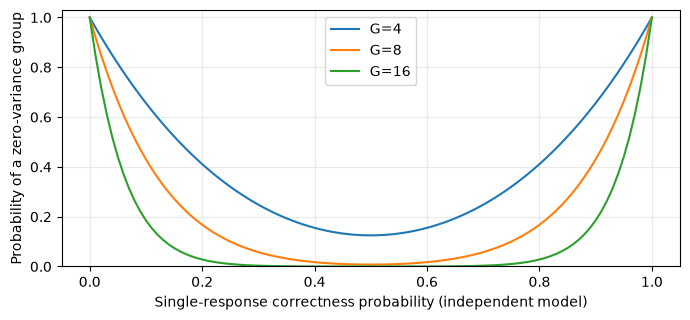

In [7]:
import matplotlib.pyplot as plt

p_values = [i / 100 for i in range(101)]
fig, ax = plt.subplots(figsize=(7, 3.3))
for group in [4, 8, 16]:
    ax.plot(p_values, [p ** group + (1 - p) ** group for p in p_values], label=f'G={group}')
ax.set(xlabel='Single-response correctness probability (independent model)',
       ylabel='Probability of a zero-variance group', ylim=(0, 1.03))
ax.legend(); ax.grid(alpha=0.25); fig.tight_layout()
plt.show()


## 6. 数据准备与划分

同一道题如果既用来训练又用来评价，模型记住题目也能提高分数。要判断训练是否能迁移到未用于更新的问题，我们必须在开始前划清数据边界，并让后续每次评估使用相同的问题集合。

### 6.1 三种集合的职责

本教程使用真实 `openai/gsm8k` 的 `main` 配置，并固定数据 revision。官方 train 再拆成训练集和 validation，官方 test 留作最后审计：

| 集合 | 什么时候使用 | 可以做什么 |
|---|---|---|
| train | 梯度更新时 | SFT 学习示范回答，或 GRPO 生成回答、评分并更新参数 |
| validation | 开发与选 checkpoint 时 | 比较配置、诊断退化，不参与本例的梯度更新 |
| test | 配置和 checkpoint 已确定后 | 最后报告；不依据它反复调参 |

validation 在训练期间被反复查看，逐渐也会影响人的选择，所以它与最终 test 的职责不同。代码把 held-out（留出）集合用于评估；留出不表示模型在预训练阶段一定没见过类似内容。

### 6.2 `prepare_data` 的处理顺序

**这是 SFT、GRPO 和生成评估共用的数据准备，不是专门给 SFT 准备标签。** 它先清洗、划分题库，再由后续路径决定如何使用数据：

| 路径 | 调用与后续处理 | 答案的用途 |
|---|---|---|
| GRPO | `prepare_data(recipe, tokenizer)` | 模型根据 prompt 自己生成；gold 只用于计算 reward |
| 可选 SFT | `prepare_data(..., include_sft_targets=True)`，随后编码和构造 completion mask | 额外保留 `sft_target`，作为 assistant 的示范回答，计算回答 token 的监督损失 |
| 生成评估 | 默认调用 `prepare_data`，选 validation 或 test | 模型自己生成，gold 用于判分，不更新参数 |

默认 `include_sft_targets=False`，因此跳过 SFT 时也会执行本节的数据准备。这里提取 gold，是因为本教程使用数值比较奖励；换成其他奖励机制时，数据中应保存对应的验证信息，GRPO 并不通用地要求一个名为 gold 的字段。

处理顺序如下：

1. **规范化题目并生成 ID。** `question_id` 把英文转为小写、合并空白，再计算 SHA-256。哈希是稳定的题目指纹，方便比较集合，而不是语义相似度判断。
2. **在各个官方 split 内去重。** 规范化后完全相同的题目只保留一次。随后检查清洗后的官方 train 和 test 是否有题目 ID 交集，有交集就报错。
3. **构造 prompt 并测量 token 长度。** 使用固定 tokenizer 的 chat template，加上 generation prompt 后计数。长度预算针对模型实际看到的输入，而不是原始题干字符数。
4. **过滤过长题目并解析 gold。** 不偷偷截断题干，避免把问题条件截掉而继续使用原答案。原始、重复、过长和保留数量都进入 audit。
5. **从官方 train 留出 validation。** 使用固定 seed 划分，然后打乱剩余训练数据，再应用 `train_limit`。最后检查 train 与 validation 的 ID 不重合。

去重不能排除“换了人名或数字但模板相同”的近似题，也不能排除模型预训练污染。audit 与哈希能证明这里执行了哪些数据操作，不能证明数据在语义上完全独立。

### 6.3 prompt 与 gold 的数据合同

一条清洗后的记录包含以下字段：

| 字段 | 内容 | 谁使用 |
|---|---|---|
| `prompt` | system 格式指令 + user 题目 | tokenizer 和策略模型 |
| `gold` | 从原始 `answer` 提取的标准数值 | 本例的 reward function 与生成评估；不是 GRPO 通用必需字段 |
| `sft_target`（可选） | 原始解答构造的推理文字与最终答案标签 | 仅 SFT 路径保留，作为 assistant 监督目标 |
| `qid` | 规范化题目哈希 | 集合检查和逐题比较 |
| `prompt_tokens` | 套用 chat template 后的输入长度 | 审计与预算分析 |

`make_prompt` 只接受 question，不接受原始完整 answer。SFT 路径可显式保留训练部分的 `sft_target`，随后将其作为 assistant 监督目标；普通 GRPO 路径不会保留该列。`gold` 作为额外 dataset 列交给评分器，`remove_unused_columns=False` 保留这些额外列。**数据记录里存有 gold，与模型输入中包含 gold 是两回事。** 下一格打印一个不含标准答案的示例 prompt，让你检查这条边界。

### 6.4 长度、样本上限与可比性

`max_prompt_tokens` 限制输入长度，`max_completion_tokens` 限制生成长度。TRL 0.28.0 的本配置不通过 `max_prompt_length` 来截断输入，题干预算在数据层实施。若把输入预算从 512 改为 1024，可能纳入此前被过滤的题目；即使随机 seed 相同，评估集合也可能变化，所以要核对问题 ID 哈希，不能只看题目总数。

`smoke` 只选最多 128 道训练题、留出 32 道 validation；`scale` 的 `train_limit=6500` 是清洗和留出之后的上限，不保证最后恰有 6500 条。模型 revision、数据 revision、seed、长度预算和 ID 列表共同决定这次实验实际使用了哪些题目。

<details><summary>练习：训练前后都评估 32 道题，为什么仍可能不能直接比较？</summary>

如果长度过滤、数据 revision、划分 seed 或题目顺序变了，两次的 32 道题可能不同。应核对 evaluation ID 哈希、prompt 和解码配置。相同样本数只说明分母相同，不说明问题难度相同。

</details>


In [8]:
def question_id(question):
    normalized = ' '.join(question.lower().split())
    return hashlib.sha256(normalized.encode()).hexdigest()

def make_prompt(question):
    return [
        {'role': 'system', 'content': SYSTEM_PROMPT},
        {'role': 'user', 'content': question},
    ]

def prepare_data(recipe, tokenizer, *, include_sft_targets=False):
    from datasets import Dataset, load_dataset
    raw = load_dataset('openai/gsm8k', 'main', revision=DATA_REVISION)
    audit = {}

    def clean(split):
        seen, records = set(), []
        duplicates = overlong = 0
        for row in raw[split]:
            qid = question_id(row['question'])
            if qid in seen:
                duplicates += 1
                continue
            seen.add(qid)
            prompt = make_prompt(row['question'])
            ids = tokenizer.apply_chat_template(prompt, tokenize=True, add_generation_prompt=True)
            if len(ids) > recipe.max_prompt_tokens:
                overlong += 1
                continue
            record = {'prompt': prompt, 'gold': parse_gold(row['answer']),
                      'qid': qid, 'prompt_tokens': len(ids)}
            if include_sft_targets and split == 'train':
                record['sft_target'] = make_sft_target(row['answer'])
            records.append(record)
        audit[split] = {'raw': len(raw[split]), 'duplicates': duplicates,
                        'overlong': overlong, 'kept': len(records)}
        if not records:
            raise ValueError(f'No usable examples in {split}')
        return Dataset.from_list(records)

    clean_train, test = clean('train'), clean('test')
    if set(clean_train['qid']) & set(test['qid']):
        raise ValueError('Official train/test question overlap detected')
    if len(clean_train) <= recipe.validation_limit:
        raise ValueError('Not enough train examples for the requested validation set')
    split = clean_train.train_test_split(test_size=recipe.validation_limit, seed=recipe.seed)
    train = split['train'].shuffle(seed=recipe.seed)
    train = train.select(range(min(recipe.train_limit, len(train))))
    validation = split['test']
    assert not (set(train['qid']) & set(validation['qid']))
    audit['selected'] = {'train': len(train), 'validation': len(validation), 'test': len(test)}
    audit['qid_hashes'] = {
        name: hashlib.sha256('\n'.join(ds['qid']).encode()).hexdigest()
        for name, ds in [('train', train), ('validation', validation), ('test', test)]
    }
    if recipe.warm_start and audit['qid_hashes'] != recipe.warm_start['data_qid_hashes']:
        raise ValueError('SFT/GRPO data split mismatch; held-out question IDs must stay fixed')
    return train, validation, test, audit


In [9]:
demo_question = 'A shop has 6 boxes with 7 apples each. How many apples are there?'
demo_prompt = make_prompt(demo_question)
assert 'gold' not in json.dumps(demo_prompt)
assert question_id(' A SHOP  has apples ') == question_id('a shop has apples')
print(json.dumps(demo_prompt, ensure_ascii=False, indent=2))
print('data contract checks passed; real dataset loads only in train/evaluate mode')


[
  {
    "role": "system",
    "content": "Solve the math problem. You may explain your reasoning. End with exactly one <answer>NUMBER</answer> tag. Do not write anything after that tag."
  },
  {
    "role": "user",
    "content": "A shop has 6 boxes with 7 apples each. How many apples are there?"
  }
]
data contract checks passed; real dataset loads only in train/evaluate mode


## 7. SFT warm start

模型如果还不会稳定给出 `<answer>` 结尾，GRPO 可能连续遇到全零奖励组。先给它看一些完整的正确示范，可以提供更密集的训练信号。本节实现 **SFT（监督微调）**，使用已有 Qwen Instruct 模型做单卡 LoRA 训练，再把训练结果作为 GRPO 的可选起点。

这不是从随机权重训练语言能力，也不是只奖励“标签写对”。SFT 直接学习训练集提供的解答文本，因此同时教输出格式和示范中的解题方式。是否改善独立数学表现，要用相同 held-out 问题验证，不能只看 SFT loss 下降。

### 7.1 示范数据

例如 GSM8K 的原始解答是：

```text
There are 6 * 7 = <<6*7=42>>42 apples.
#### 42
```

我们移除 `<<...>>` 计算器标注，保留可读的解答文字，并将最终答案写成统一格式：

```text
There are 6 * 7 = 42 apples.
<answer>42</answer>
```

`make_sft_target` 只处理数据集给出的解答，不执行其中的表达式。它复用同一个 gold parser，并检查转换后的文本能通过 verifier。如果原数据缺少唯一分隔符，或解答里已经有冲突标签，就报错。

SFT 与 GRPO 复用 `prepare_data` 的去重、长度预算、固定 seed 和 train/validation/test 划分。**只有训练部分进入参数更新；validation 的示范只用于 teacher-forced loss 检查，test 不构造 SFT 目标。** SFT 的完整解答还要包含结束 token；如果目标超出回答预算，整条过滤并记录，不截断成一条没有最终答案的示范。这个过滤在划分之后进行，不改变独立评估的问题 ID。


In [10]:
def make_sft_target(answer):
    gold = parse_gold(answer)
    reasoning = re.sub(r'<<[^<>]*>>', '', answer.split('####')[0]).strip()
    target = f'{reasoning}\n<answer>{gold}</answer>' if reasoning else f'<answer>{gold}</answer>'
    if parse_completion(target) != Decimal(gold):
        raise ValueError('SFT demonstration violates the final-answer protocol')
    return target


def encode_sft_example(prompt, target, tokenizer, recipe):
    prompt_ids = tokenizer.apply_chat_template(prompt, tokenize=True, add_generation_prompt=True)
    full_ids = tokenizer.apply_chat_template(
        prompt + [{'role': 'assistant', 'content': target}], tokenize=True, add_generation_prompt=False)
    if not prompt_ids or full_ids[:len(prompt_ids)] != prompt_ids:
        raise ValueError('Chat template does not preserve the prompt token prefix; cannot mask safely')
    response_ids = full_ids[len(prompt_ids):]
    if not response_ids or tokenizer.eos_token_id not in response_ids:
        raise ValueError('SFT target must include a normal assistant end-of-turn token')
    if len(prompt_ids) > recipe.max_prompt_tokens or len(response_ids) > recipe.max_completion_tokens:
        return None  # Drop the whole example; never cut off the target or EOS.
    return {'input_ids': full_ids, 'attention_mask': [1] * len(full_ids),
            'completion_mask': [0] * len(prompt_ids) + [1] * len(response_ids)}


def prepare_sft_data(recipe, tokenizer):
    from datasets import Dataset
    train_ds, validation_ds, _, data_audit = prepare_data(recipe, tokenizer, include_sft_targets=True)
    sft_audit = {}

    def encode(ds, name):
        records, qids = [], []
        for row in ds:
            record = encode_sft_example(row['prompt'], row['sft_target'], tokenizer, recipe)
            if record is not None:
                records.append(record)
                qids.append(row['qid'])
        sft_audit[name] = {'selected': len(ds), 'kept': len(records), 'overlong': len(ds) - len(records),
                           'used_qid_sha256': hashlib.sha256('\n'.join(qids).encode()).hexdigest()}
        if not records:
            raise ValueError(f'No complete SFT targets fit the {name} token budget')
        return Dataset.from_list(records)

    train, validation = encode(train_ds, 'train'), encode(validation_ds, 'validation')
    return train, validation, {'data': data_audit, 'sft': sft_audit}


In [11]:
demo_sft_target = make_sft_target('There are 6 * 7 = <<6*7=42>>42 apples. #### 42')
print(demo_sft_target)
assert parse_completion(demo_sft_target) == Decimal('42')


There are 6 * 7 = 42 apples.
<answer>42</answer>


### 7.2 Assistant loss 与 teacher forcing

SFT 的监督目标是：给定题目和示范中已经出现的前文，预测示范的下一个 token。这叫 **teacher forcing**。例如要预测 `42`，模型看到的是题目和标准解答前缀；它不用先随机生成完整回答，也没有 G 个候选之间的比较。

把 prompt 记为 x、assistant 目标 token 记为 $y_1,\ldots,y_T$，只在有效 assistant 位置平均负对数概率：

$$L_{\mathrm{SFT}}=-\frac{1}{T}\sum_{t=1}^{T}\log\pi_\theta(y_t\mid x,y_{<t}).$$

| 序列位置 | 作为模型上下文 | 是否直接计算 SFT loss |
|---|---|---|
| system 格式要求、user 问题、assistant 开头标记 | 是 | 否，label=-100 |
| assistant 的示范推理与最终答案 | 是，按因果顺序使用此前 token | 是 |
| 正常结束 token（EOS） | 是 | 是，让模型学习结束 |
| batch 补齐用的 padding | 由 attention mask 忽略 | 否，label=-100 |

labels 与 input_ids 对齐，因果语言模型的 loss 内部执行一次 next-token shift，不在数据层再手动移位。**训练时目标文本出现在序列中，是受因果 attention 约束的监督学习；生成评估时仍只提供 prompt，不能把示范或 gold 拼到问题里。**

Qwen chat template 不一定提供 Jinja 的 assistant generation mask，所以这里不直接假定 `assistant_only_loss=True` 可用。我们分别 tokenize prompt 与完整对话，严格验证 prompt token 是完整序列的前缀，再显式构造 `completion_mask`。TRL collator 据此把 prompt/padding 的 label 设为 -100；真实 EOS 即使与 pad 使用相同 ID，也保留监督。下面用真实 collator 检查这个边界。[固定版本 SFT 源码](https://github.com/huggingface/trl/blob/v0.28.0/trl/trainer/sft_trainer.py)

配置使用 `SFTTrainer`、completion-only loss、不 packing，长度过滤已在数据层执行。默认单卡 b=2、K=4，每次更新综合 8 个示范；SFT 不使用 G，也没有 reward、advantage 或 reference KL。`learning_rate=2e-5`、20 steps 是短链路起点，不是最优配置。[SFTTrainer API](https://huggingface.co/docs/trl/v0.28.0/en/sft_trainer)


In [12]:
def make_sft_config(recipe, *, cpu_validation=False):
    from trl import SFTConfig
    return SFTConfig(
        output_dir=recipe.output_dir, max_steps=recipe.max_steps,
        per_device_train_batch_size=recipe.micro_batch, per_device_eval_batch_size=2,
        gradient_accumulation_steps=recipe.grad_accum, learning_rate=recipe.learning_rate,
        warmup_steps=max(1, recipe.max_steps // 20), lr_scheduler_type='cosine',
        max_grad_norm=1.0, optim='adamw_torch',
        bf16=not cpu_validation, use_cpu=cpu_validation,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={'use_reentrant': False},
        model_init_kwargs={'revision': recipe.model_revision, 'dtype': 'float32' if cpu_validation else 'bfloat16',
                           'attn_implementation': 'eager' if cpu_validation else 'sdpa'},
        # Qwen's template need not implement Jinja generation/assistant masks.
        # We supply and test an explicit completion_mask instead.
        completion_only_loss=True, assistant_only_loss=False,
        dataset_kwargs={'skip_prepare_dataset': True}, max_length=None,
        packing=False, padding_free=False, remove_unused_columns=False,
        eval_strategy='steps', eval_steps=max(5, recipe.max_steps // 10),
        save_strategy='steps', save_steps=max(5, recipe.max_steps // 10), save_total_limit=3,
        save_only_model=False, logging_steps=1, logging_nan_inf_filter=False,
        seed=recipe.seed, data_seed=recipe.seed, report_to='none', push_to_hub=False,
    )


def sft_mask_self_test():
    from trl.trainer.sft_trainer import DataCollatorForLanguageModeling
    # EOS is 2 here. Using EOS as padding must not erase the real EOS label.
    collator = DataCollatorForLanguageModeling(pad_token_id=2, completion_only_loss=True)
    batch = collator([
        {'input_ids': [10, 11, 20, 21, 2], 'completion_mask': [0, 0, 1, 1, 1]},
        {'input_ids': [10, 20, 2], 'completion_mask': [0, 1, 1]},
    ])
    assert batch['labels'].tolist() == [[-100, -100, 20, 21, 2], [-100, 20, 2, -100, -100]]
    assert batch['attention_mask'].tolist() == [[1, 1, 1, 1, 1], [1, 1, 1, 0, 0]]
    print('SFT assistant/prompt/padding/EOS mask checks passed')


In [13]:
try:
    from trl import SFTConfig
except ImportError:
    print('TRL 未安装；SFT mask/API 检查需第 1 节的独立环境。')
else:
    sft_mask_self_test()
    sft_checked = make_sft_config(make_recipe('smoke', SFT_ARTIFACT_ROOT), cpu_validation=True)
    assert sft_checked.completion_only_loss and not sft_checked.packing
    print('SFT config: completion-only loss; no packing; model not loaded')


SFT assistant/prompt/padding/EOS mask checks passed
SFT config: completion-only loss; no packing; model not loaded


### 7.3 从 SFT 接到 GRPO

SFT 与 GRPO 使用两套独立的 optimizer、schedule 和训练目录。SFT 的 checkpoint 用于继续 SFT，不能作为 GRPO 的 `--resume`。GRPO 是一段新训练，只继承 SFT 后的模型参数。

| SFT 产物 | 内容 | 用途 |
|---|---|---|
| `checkpoint-N/` | adapter、optimizer、scheduler、RNG、Trainer 状态 | SFT 中断后恢复 |
| `final-adapter/` | 训练后的 LoRA adapter 与 tokenizer | 保留可单独加载的 adapter |
| `merged/` | 基座加 SFT LoRA 后的完整权重、tokenizer、`sft-export.json` | 作为 GRPO 起点和 SFT 后评估对象 |

我们显式合并 SFT LoRA，然后在 merged 基座上新建 GRPO LoRA。这让“禁用 GRPO adapter”得到 SFT 后的 reference，而不是退回最初的 Instruct 模型。如果把两个阶段混用同一个 adapter，reference 的语义就需要额外处理；本例通过合并明确这条边界。[PEFT LoRA 合并接口](https://huggingface.co/docs/peft/v0.18.0/package_reference/lora)

`with_sft_start` 校验基座来源、数据 revision、prompt、划分 seed、长度与样本配置，并核对导出文件的 SHA-256；GRPO 准备数据时再次检查题目 ID 哈希。改变了文件或留出题目就拒绝继续，防止误把另一个 SFT 实验接入。已完成的 merged 导出保持不可覆盖；新 SFT 实验要选择新目录。哈希用于识别这个导出，不是模型质量指标。

下面定义训练和导出函数。它们在第 9 节的公共日志/目录函数定义完成后，由统一入口调用；默认不加载模型。这个 SFT 示例仅支持单卡 smoke，原来的四卡 learner/vLLM scale 路径仍然可以直接运行 GRPO，未在这里扩展为多卡 SFT。


In [14]:
def model_file_hashes(directory):
    directory = Path(directory)
    hashes = {}
    for path in sorted(directory.rglob('*')):
        if path.is_file() and path.name != 'sft-export.json':
            digest = hashlib.sha256()
            with path.open('rb') as handle:
                for block in iter(lambda: handle.read(1024 * 1024), b''):
                    digest.update(block)
            hashes[str(path.relative_to(directory))] = digest.hexdigest()
    return hashes


def export_sft_model(model, tokenizer, recipe, audit):
    destination = Path(recipe.output_dir) / 'merged'
    if destination.exists():
        raise FileExistsError('SFT merged export already exists; use a fresh SFT run directory')
    merged = model.merge_and_unload(safe_merge=True)
    merged.save_pretrained(destination)
    tokenizer.save_pretrained(destination)
    export = {'stage': 'sft', 'recipe': asdict(recipe), 'data_revision': DATA_REVISION,
              'system_prompt': SYSTEM_PROMPT, 'data_qid_hashes': audit['data']['qid_hashes'],
              'sft_audit': audit['sft'], 'file_sha256': model_file_hashes(destination)}
    save_manifest(destination / 'sft-export.json', export)
    return destination


def with_sft_start(recipe, directory):
    if recipe.profile != 'smoke' or recipe.warm_start is not None:
        raise ValueError('This SFT handoff supports a fresh smoke recipe only')
    directory = Path(directory).resolve()
    export_path = directory / 'sft-export.json'
    export = json.loads(export_path.read_text())
    if export.get('stage') != 'sft' or (directory / 'adapter_config.json').exists():
        raise ValueError('GRPO needs the merged SFT model, not an unmerged adapter')
    for key in ['model', 'model_revision', 'profile', 'seed', 'validation_limit', 'train_limit',
                'max_prompt_tokens', 'max_completion_tokens']:
        if export['recipe'].get(key) != getattr(recipe, key):
            raise ValueError(f'SFT initialization mismatch: {key}')
    if export['data_revision'] != DATA_REVISION or export['system_prompt'] != SYSTEM_PROMPT:
        raise ValueError('SFT data revision or prompt protocol differs from GRPO')
    if export['file_sha256'] != model_file_hashes(directory):
        raise ValueError('SFT export files changed after training')
    provenance = {'path': str(directory), 'export_sha256': hashlib.sha256(export_path.read_bytes()).hexdigest(),
                  'data_qid_hashes': export['data_qid_hashes'], 'file_sha256': export['file_sha256']}
    return replace(recipe, model=str(directory), model_revision=None, warm_start=provenance)


def train_sft(recipe, resume=None, *, cpu_validation=False):
    from transformers import AutoTokenizer, set_seed
    from trl import SFTTrainer
    if recipe.profile != 'smoke' or recipe.expected_world_size != 1 or recipe.warm_start:
        raise ValueError('SFT warm start is a single-GPU smoke demonstration')
    if recipe.max_steps <= 0:
        raise ValueError('SFT max_steps must be positive')
    recipe = replace(recipe, use_vllm=False, deepspeed=None)
    check_runtime(recipe, cpu_validation=cpu_validation)
    if (Path(recipe.output_dir) / 'merged').exists():
        raise FileExistsError('Completed SFT export is immutable; choose a fresh output root')
    set_seed(recipe.seed)
    tokenizer = AutoTokenizer.from_pretrained(recipe.model, revision=recipe.model_revision, padding_side='right')
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    train_ds, validation_ds, audit = prepare_sft_data(recipe, tokenizer)
    manifest = {**runtime_manifest(recipe, tokenizer, audit), 'stage': 'sft',
                'objective': 'assistant completion cross-entropy', 'packing': False}
    protect_run_dir(recipe, manifest, resume)
    config = make_sft_config(recipe, cpu_validation=cpu_validation)
    trainer = SFTTrainer(model=recipe.model, args=config, processing_class=tokenizer,
                         train_dataset=train_ds, eval_dataset=validation_ds,
                         peft_config=make_lora_config(), callbacks=[make_metrics_callback(recipe.output_dir)])
    Path(recipe.output_dir).mkdir(parents=True, exist_ok=True)
    save_manifest(Path(recipe.output_dir) / 'manifest.json', manifest)
    save_manifest(Path(recipe.output_dir) / 'installed-packages.json',
                  {d.metadata['Name']: d.version for d in importlib.metadata.distributions()})
    result = trainer.train(resume_from_checkpoint=resume)
    adapter = Path(recipe.output_dir) / 'final-adapter'
    trainer.save_model(str(adapter))
    tokenizer.save_pretrained(adapter)
    trainer.save_state()
    save_manifest(Path(recipe.output_dir) / 'train-summary.json', result.metrics)
    model = trainer.accelerator.unwrap_model(trainer.model)
    merged = export_sft_model(model, tokenizer, recipe, audit)
    print(json.dumps({'sft_merged_model': str(merged), 'audit': audit}, indent=2))
    return str(merged)


### 7.4 运行与效果判断

在最前面的初始化单元设置 `RUN_SFT=True` 可执行 SFT；同时设置 `RUN_TRAIN=True` 会在 SFT 完成后继续 GRPO。也可以保持 `RUN_SFT=False`，将 `SFT_MODEL` 设为已有的 `merged/`，避免重做 SFT。默认两个开关都关闭。完整终端命令在第 11 节，推荐把各阶段放进独立进程以释放显存。

比较三个点：**原 Instruct、SFT 后、SFT+GRPO 后**。全部使用同一组 validation ID、相同 prompt 和 greedy 解码。SFT eval loss 是在标准解答前缀下预测下一个 token 的误差，不能替代模型自己从头作答的准确率，也不能与 GRPO 的 eval loss 直接比较。

<details><summary>练习：SFT loss 下降，但独立评估仍大量缺少结束标签，先检查什么？</summary>

先检查目标中是否真的包含最终标签和 EOS、它们的 label 是否被错误 mask、过长目标是否被截断，以及训练和生成是否使用同一个 chat template。再检查训练步数和示范覆盖。teacher-forced loss 下降只说明更能预测示范 token，不保证自由生成时已经稳定遵守协议。

</details>


## 8. 训练配置

参数应服务于一个明确目的：确定更新目标、保留探索、控制显存，以及让实验能保存和恢复。`make_trl_config` 把前面定义的 recipe 映射成固定版本的 `GRPOConfig`；`check_runtime` 则在加载真实训练前检查依赖、CUDA、bf16 与训练进程数。

### 8.1 配置一览

| 配置 | 这里的选择 | 原因与边界 |
|---|---|---|
| `bf16` | 需要 CUDA GPU 支持 | 比 fp16 有更大的指数范围，仍须监控非有限 loss |
| gradient checkpointing | 开启 | 反向时重算部分前向计算，以计算时间换显存 |
| `beta=0.02` | 显式保留 reference KL | 约束相对起点的偏移，不是奖励函数中的格式分 |
| `num_iterations=2` | 同一 rollout 训练两轮 | 增加数据复用，也增大后续更新的策略差异 |
| `loss_type="dr_grpo"` | 固定回答长度上限归一化 | 与按有效 token 总数归一化的 DAPO 不同 |
| `scale_rewards="group"` | 同题均值和标准差 | 决定奖励如何转换成组内优势 |
| `mask_truncated_completions=True` | 屏蔽被判定为截断的回答 | 截断太多会丢失大量有效训练位置 |
| `temperature=0.8`、`top_p=0.95` | 随机采样 | 提供探索；独立评估使用 greedy |
| checkpoint | 保存训练状态 | 推理用 final model 不能代替训练 checkpoint |

### 8.2 LoRA 与全参数更新

在 `smoke` 中，基座权重冻结，在注意力投影和前馈网络（MLP）投影上训练 LoRA。代码选择 `r=16`、`lora_alpha=32`、`lora_dropout=0`：r 是低秩矩阵的内部维度，影响可训练参数量与表达能力；alpha 控制附加更新的缩放。它们是这个例子的配置，不是所有任务的最佳值。

LoRA 减少了需要梯度和 optimizer 状态的参数，但模型仍需加载基座，并保存计算 adapter 梯度所需的激活。在原 Instruct 基座上新建 adapter 时，禁用它可得到原基座的 reference 概率；选择 `--sft-model` 时，SFT 权重已合并进基座，新 GRPO adapter 被禁用后得到的是 SFT 后模型的 reference 概率；全参数 `scale` 不能靠禁用 adapter 恢复起点，因此需要额外 reference 参数。这个区别会影响显存预算。

### 8.3 显存技巧各自节省什么

bf16 降低许多张量的存储成本，并提供较宽的数值范围，但不是数值稳定性的保证。gradient checkpointing 减少部分中间激活的保存，在反向时重算；它与磁盘上的 `checkpoint-N` 同名，但前者是计算策略，后者是恢复文件，作用完全不同。

ZeRO-3 在训练卡之间分片参数、梯度和 optimizer 状态，需要计算某层时再协调获取相应参数。它增加通信与调度，也不能消除激活、生成 KV cache 和保存全模型时的峰值。配套 DeepSpeed JSON 把 batch 等字段设为 `auto`，由训练配置对齐，避免在两处手动维护互相矛盾的数值。[DeepSpeed ZeRO 说明](https://www.deepspeed.ai/tutorials/zero/)

### 8.4 探索、更新速度与截断

`temperature` 改变采样分布的尖锐程度，`top_p` 限制候选 token 的累计概率范围。更随机不必然更有效：它可能增加回答差异，也可能产生更多无效格式或低质量回答。G、温度、题目难度和输出长度一起决定一组中能否出现可用的奖励差异。

学习率决定每次参数更新走多远，`num_iterations` 决定同一批回答要用几次，两者都会影响当前策略相对 old policy 的偏移。这里 smoke 学习率为 `5e-6`，scale 为 `1e-6`，使用 cosine schedule、至少 1 步的 warmup 和 `max_grad_norm=1.0`。梯度裁剪限制梯度范数，目标函数 clipping 限制概率比收益，它们也是两个不同机制。

如果回答达到预算却没有正常结束，本配置会将其屏蔽出损失。第 4 节的 verifier 仍只是文本格式与数值检查：它不负责判断是否因 token 上限结束。因此，某个文本通过 parser，与它最终是否参与训练 loss，不是同一个判断。要一起看截断率和有效 token 数，而不能只看平均 reward。

### 8.5 vLLM 校正与运行时检查

scale 采用不同的训练和生成后端，即使权重相同，计算精度和实现也可能带来概率差异。配置启用 `vllm_importance_sampling_correction`，采用 `token_truncate` 并将校正权重上限设为 2.0。这个上限属于后端差异校正，不是 GRPO 的 `epsilon=0.2`；后者比较当前策略与训练侧 old policy 的概率。

校正不会自动修复 server 长期没有更新权重的问题。仍需同步正确的策略版本，并限制回答复用。`check_runtime` 要求实际 `WORLD_SIZE` 与 profile 一致，所以 scale 计划为 4 张训练卡时，误以单进程运行会直接失败。W 不包括另外 4 张只负责生成的 GPU。

下一格在 CPU 上只构造 config，检查 `generation_batch_size=8` 等 API 合同，不加载模型。如果 TRL 没安装，会提示使用独立环境；这格通过也不能证明 CUDA kernel、NCCL 或 vLLM 权重同步已经工作。


In [15]:
def check_runtime(recipe, *, cpu_validation=False):
    import torch
    for package, expected in LIBRARY_VERSIONS.items():
        actual = importlib.metadata.version(package)
        if actual != expected:
            raise RuntimeError(f'{package}: expected {expected}, got {actual}; use the dedicated environment')
    if not cpu_validation and not torch.cuda.is_available():
        raise RuntimeError('Real training requires Linux/NVIDIA CUDA; CPU checks can still run')
    if not cpu_validation and not torch.cuda.is_bf16_supported():
        raise RuntimeError('This recipe requires CUDA bfloat16 support')
    actual_world = int(os.environ.get('WORLD_SIZE', '1'))
    if actual_world != recipe.expected_world_size:
        raise RuntimeError(f'Expected WORLD_SIZE={recipe.expected_world_size}, got {actual_world}')
    if recipe.use_vllm:
        if importlib.metadata.version('vllm') != '0.12.0':
            raise RuntimeError('scale expects vllm==0.12.0 on both learner and server')
        if not Path(recipe.deepspeed).exists():
            raise FileNotFoundError(recipe.deepspeed)
    return actual_world

def make_trl_config(recipe, *, cpu_validation=False):
    from trl import GRPOConfig
    kwargs = dict(
        output_dir=recipe.output_dir, per_device_train_batch_size=recipe.micro_batch,
        gradient_accumulation_steps=recipe.grad_accum,
        steps_per_generation=recipe.grad_accum,
        num_generations=recipe.group_size, num_generations_eval=2,
        per_device_eval_batch_size=2, max_completion_length=recipe.max_completion_tokens,
        num_iterations=recipe.num_iterations,
        beta=recipe.beta, loss_type='dr_grpo', scale_rewards='group',
        epsilon=0.2, temperature=0.8, top_p=0.95,
        mask_truncated_completions=True,
        learning_rate=recipe.learning_rate, lr_scheduler_type='cosine',
        warmup_steps=max(1, recipe.max_steps // 20), max_steps=recipe.max_steps,
        max_grad_norm=1.0, optim='adamw_torch',
        bf16=not cpu_validation, use_cpu=cpu_validation,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant': False},
        model_init_kwargs={'revision': recipe.model_revision,
                           'dtype': 'float32' if cpu_validation else 'bfloat16',
                           'attn_implementation': 'eager' if cpu_validation else 'sdpa'},
        disable_dropout=True, remove_unused_columns=False,
        seed=recipe.seed, data_seed=recipe.seed,
        eval_strategy='steps', eval_steps=max(5, recipe.max_steps // 10),
        save_strategy='steps', save_steps=max(5, recipe.max_steps // 10),
        save_total_limit=3, save_only_model=False,
        logging_steps=1, report_to='none', log_completions=False,
        ddp_find_unused_parameters=False, push_to_hub=False,
        use_vllm=recipe.use_vllm and not cpu_validation,
        deepspeed=recipe.deepspeed if not cpu_validation else None,
    )
    if kwargs['use_vllm']:
        kwargs.update(vllm_mode='server', vllm_server_base_url=recipe.vllm_url,
                      vllm_importance_sampling_correction=True,
                      vllm_importance_sampling_mode='token_truncate',
                      vllm_importance_sampling_cap=2.0)
    return GRPOConfig(**kwargs)


In [16]:
# CPU 可以真实构造 TRL config，检测 API 兼容性，不加载模型。
try:
    from trl import GRPOConfig
except ImportError:
    print('TRL 未安装；请使用第 1 节的独立环境。奖励和数学检查已可运行。')
else:
    checked = make_trl_config(make_recipe('smoke', ARTIFACT_ROOT), cpu_validation=True)
    assert checked.generation_batch_size == 8
    assert checked.steps_per_generation == 4
    print('TRL API check:', {'generation_batch_size': checked.generation_batch_size,
                             'num_iterations': checked.num_iterations,
                             'loss_type': checked.loss_type})


TRL API check: {'generation_batch_size': 8, 'num_iterations': 2, 'loss_type': 'dr_grpo'}


## 9. 日志与断点恢复

一次长训练可能因进程退出、节点回收或资源问题中断。要接着训练，既要知道“模型走到了哪里”，也要知道“优化器准备怎样继续走”。这一节把实验身份、运行指标和可恢复状态分开保存。

### 9.1 一次运行留下哪些文件

| 产物 | 记录什么 | 用途 |
|---|---|---|
| `manifest.json` | recipe、核心库版本、模型配置中的 revision、数据 ID 哈希、prompt/template、GPU 等 | 判断是不是同一项实验 |
| `installed-packages.json` | 已安装 Python 包及版本 | 排查主依赖之外的环境差异 |
| `metrics.jsonl` | step、时间戳与 Trainer 提供的指标 | 追踪训练与评估过程 |
| `checkpoint-N/` | 模型或 adapter、optimizer、scheduler、RNG、Trainer 状态等 | 恢复训练 |
| `final/` | 最终推理权重或 adapter，以及 tokenizer | 独立评估和推理 |
| `train-summary.json` | 本次 train 调用返回的汇总指标 | 查看这次调用的总体统计 |

manifest 中的数据 ID 哈希描述选中了哪些题，chat template 哈希描述消息如何变成输入。它们帮助定位“同一个模型名、同一份代码，为什么结果不同”，但不能保证跨硬件的数值运算完全相同。

### 9.2 为什么只有模型权重不够

假设模型在第 10 步中断。只加载第 10 步权重、重新创建 optimizer，会丢掉 AdamW 的历史动量；重新创建 scheduler，学习率可能从错误位置开始；丢掉 RNG 状态，采样随机序列也会改变。于是这更像“以该模型为起点的新实验”，不能默认等价于接着第 11 步训练。

`checkpoint-N` 因此需要保留完整训练状态。`final/` 主要用于推理：LoRA profile 保存 adapter，scale 保存全模型；它不是可恢复 checkpoint 的替代品。训练结束时写出的 Trainer state 也不意味着 final 目录已经带齐所有恢复组件。

### 9.3 恢复前的保护检查

`protect_run_dir` 要求 `--resume` 指向本次运行目录内的 `checkpoint-N`，里面有 `trainer_state.json`，且当前 manifest 与原文件完全一致。没有 resume 时，非空运行目录会被拒绝，防止把不同实验的日志、权重和状态混在一起。

例如，smoke 原计划为 20 步，从 `checkpoint-10` 恢复后应向原定第 20 步继续，不是“再额外训练 20 步”。更改 world size、数据、模型路径或原计划配置可能触发 manifest 不匹配。若目的是开始一个不同设置的实验，应使用新目录，并明确记录它是新实验。

这些检查是必要的保护，不能证明每个 checkpoint 分片都完整，也不能保证 GRPO 内存中的 rollout 缓冲逐项恢复。尤其一批回答复用两轮时，中断可能发生在两轮之间。CPU 集成检查证明训练状态可以加载并继续推进步数，没有证明恢复后的采样轨迹与未中断运行逐 bit 一致。

### 9.4 多进程写入与非有限值

rank 是训练进程的编号。所有 rank 都参与训练和需要的分布式保存，但只让 rank 0 写 manifest 与汇总日志，避免多个进程同时追加同一文件。`save_manifest` 先写临时文件再替换目标，减少读到半份 JSON 的机会；它不是整个 checkpoint 的跨节点事务。

配置每个 optimizer step 记录训练日志，callback 把收到的日志追加到 JSONL，评估事件也可能产生额外记录。不能假定所有指标在每一行都存在；某些字段只在训练、评估或开启相应功能时出现。

默认 Trainer 可以过滤非有限 loss 的日志显示，本例关闭该过滤，并检查指定的 `loss`、`reward`、`kl` 及相应 eval 字段，遇到 NaN/Infinity 时报错。它只检查收到的日志值，不是所有参数、梯度和通信状态的完整审计；分布式 launcher 还需要负责统一终止或重启其他 rank。

### 9.5 下面的 `train` 如何把流程接起来

训练入口依次检查运行时、加载 tokenizer、准备数据、生成 manifest、检查目录，再构造 LoRA 和 `GRPOTrainer`。Trainer 接收 `correctness_reward` 和私有 gold 列，执行训练后保存模型与汇总。同步 barrier 让各 rank 在目录检查和保存边界等待彼此，避免某个 rank 过早创建目录，干扰其他 rank 的初始检查。

紧接着的入口单元分别由 `RUN_SFT`、`RUN_TRAIN` 控制：可只做 SFT、只做 GRPO，或先 SFT 再 GRPO；默认都不执行。两者都打开时，先保存 SFT merged 模型，再用它初始化 GRPO。notebook 直接训练仅支持 smoke。scale 通过第 11 节的 launcher 启动，让每个训练 rank 都执行同一份脚本。


In [17]:
def runtime_manifest(recipe, tokenizer, audit):
    import torch
    return {
        'recipe': asdict(recipe), 'data_revision': DATA_REVISION,
        'data_audit': audit, 'system_prompt': SYSTEM_PROMPT,
        'chat_template_sha256': hashlib.sha256(tokenizer.chat_template.encode()).hexdigest(),
        'libraries': {name: importlib.metadata.version(name) for name in LIBRARY_VERSIONS},
        'torch': torch.__version__, 'cuda': torch.version.cuda,
        'world_size': int(os.environ.get('WORLD_SIZE', '1')),
        'scale_libraries': {name: importlib.metadata.version(name) for name in ['vllm', 'deepspeed']} if recipe.use_vllm else {},
        'gpu': torch.cuda.get_device_name() if torch.cuda.is_available() else None,
    }

def save_manifest(path, manifest):
    path = Path(path)
    tmp = path.with_suffix('.json.tmp')
    tmp.write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + '\n')
    tmp.replace(path)

def protect_run_dir(recipe, manifest, resume):
    out = Path(recipe.output_dir)
    manifest_path = out / 'manifest.json'
    if resume:
        checkpoint = Path(resume).resolve()
        if checkpoint.parent != out.resolve() or not re.fullmatch(r'checkpoint-\d+', checkpoint.name):
            raise ValueError('Resume checkpoint must be checkpoint-N inside this run directory')
        if not (checkpoint / 'trainer_state.json').is_file():
            raise ValueError('Missing trainer_state.json; final model is not a training checkpoint')
        if not manifest_path.is_file() or json.loads(manifest_path.read_text()) != manifest:
            raise ValueError('Resume manifest mismatch; restore the original recipe/runtime/data')
    elif out.exists() and any(out.iterdir()):
        raise FileExistsError(f'{out} is not empty; use a fresh output root or --resume')

def make_metrics_callback(output_dir):
    from transformers import TrainerCallback

    class MetricsCallback(TrainerCallback):
        def on_log(self, args, state, control, logs=None, **kwargs):
            if not state.is_world_process_zero or not logs:
                return
            for key in ['loss', 'reward', 'kl', 'eval_loss', 'eval_reward', 'eval_kl']:
                value = logs.get(key)
                if isinstance(value, (int, float)) and not math.isfinite(value):
                    raise FloatingPointError(f'Non-finite {key} at step {state.global_step}')
            row = {'step': state.global_step, 'timestamp': time.time(), **logs}
            with (Path(output_dir) / 'metrics.jsonl').open('a') as handle:
                handle.write(json.dumps(row) + '\n')
    return MetricsCallback()

def make_lora_config():
    from peft import LoraConfig
    return LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0,
                      target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj',
                                      'gate_proj', 'up_proj', 'down_proj'],
                      bias='none', task_type='CAUSAL_LM')


def train(recipe, resume=None):
    from transformers import AutoTokenizer, set_seed
    from trl import GRPOTrainer
    check_runtime(recipe)
    set_seed(recipe.seed)
    tokenizer = AutoTokenizer.from_pretrained(recipe.model, revision=recipe.model_revision,
                                              padding_side='left')
    if not tokenizer.chat_template:
        raise ValueError('A chat model with a chat template is required')
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    train_ds, validation_ds, _, audit = prepare_data(recipe, tokenizer)
    manifest = runtime_manifest(recipe, tokenizer, audit)
    protect_run_dir(recipe, manifest, resume)
    from accelerate import PartialState
    PartialState().wait_for_everyone()  # 所有 rank 先通过目录检查，再允许 Trainer 创建目录。
    config = make_trl_config(recipe)
    config.logging_nan_inf_filter = False
    peft = make_lora_config() if recipe.lora else None
    trainer = GRPOTrainer(
        model=recipe.model, args=config, processing_class=tokenizer,
        reward_funcs=correctness_reward, train_dataset=train_ds,
        eval_dataset=validation_ds, peft_config=peft,
        callbacks=[make_metrics_callback(recipe.output_dir)],
    )
    if trainer.is_world_process_zero():
        Path(recipe.output_dir).mkdir(parents=True, exist_ok=True)
        save_manifest(Path(recipe.output_dir) / 'manifest.json', manifest)
        packages = {d.metadata['Name']: d.version for d in importlib.metadata.distributions()}
        save_manifest(Path(recipe.output_dir) / 'installed-packages.json', packages)
        print(json.dumps({'batch': batch_plan(recipe), 'audit': audit}, indent=2))
    trainer.accelerator.wait_for_everyone()
    result = trainer.train(resume_from_checkpoint=resume)
    final = Path(recipe.output_dir) / 'final'
    trainer.save_model(str(final))
    trainer.save_state()
    if trainer.is_world_process_zero():
        tokenizer.save_pretrained(final)
        save_manifest(Path(recipe.output_dir) / 'train-summary.json', result.metrics)
    trainer.accelerator.wait_for_everyone()
    return result.metrics


In [18]:
selected_sft = SFT_MODEL
if RUN_SFT:
    sft_recipe = replace(make_recipe(PROFILE, SFT_ARTIFACT_ROOT), max_steps=SFT_STEPS, learning_rate=2e-5)
    selected_sft = train_sft(sft_recipe)
else:
    print('SFT 未执行。RUN_SFT=True 可训练；SFT_MODEL 可选择已有 merged/ 导出。')

recipe = make_recipe(PROFILE, ARTIFACT_ROOT)
if selected_sft is not None:
    recipe = with_sft_start(recipe, selected_sft)
if RUN_TRAIN:
    if PROFILE != 'smoke':
        raise RuntimeError('Notebook 只直接运行单卡 smoke；scale 用后面的 accelerate 命令')
    train_summary = train(recipe)
    print(train_summary)
else:
    print('GRPO 未执行。设置 RUN_TRAIN=True，或使用配套脚本启动 CUDA 训练。')


SFT 未执行。RUN_SFT=True 可训练；SFT_MODEL 可选择已有 merged/ 导出。
GRPO 未执行。设置 RUN_TRAIN=True，或使用配套脚本启动 CUDA 训练。


## 10. 独立评估

**训练 reward 上升，是否就表示模型更会做题？不一定。** 训练 reward 来自随机采样的多个回答；独立评估这里测的是固定题目上 greedy 单次作答的表现。两者的问题集合、解码方式、样本相关性与截断处理不同，必须分开观察。

### 10.1 固定什么，才能比较训练前后

先在原 Instruct 模型上评估，保存 baseline；若启用 SFT，还要用 `--sft-model` 评估 SFT 后、GRPO 前的模型，形成第三个对照点。训练后加载指定 checkpoint 或 final，使用相同的问题 ID、system prompt、chat template、长度预算和 greedy 解码再次评估。greedy 指每个生成位置选择当前概率最高的 token，本例通过 `do_sample=False` 实现。

训练时 temperature=0.8、每题采样 G 次，是为探索和构造组内比较；评估时每题只生成一次。G 不会让这里的 accuracy 自动变成“G 个候选里只要一个答对就算对”。如果想测 pass@k 或多数投票，需要另设评估协议和采样预算，不能沿用这个数值的名称。

### 10.2 每个指标回答什么问题

| 指标 | 这里如何计算 | 如何解释 |
|---|---|---|
| greedy accuracy | 格式有效且数值正确的题数 / 全部题数 | 本输出协议下的单次作答成功率 |
| format rate | `parse_completion` 成功的题数 / 全部题数 | 是否按协议交付最终数值 |
| truncation rate | 生成 token 中未出现 EOS 的题数 / 全部题数 | 有多少回答没有正常结束 |
| mean output tokens | 生成 token 数的平均值 | 回答长度与生成成本的一个侧面 |
| Wilson 95% interval | 根据答对数和题目数计算 | 小样本准确率的不确定性 |
| generation output token/s | 输出 token 总数 / 逐题 `generate` 的计时时间 | 此 evaluator 的生成速度 |

EOS 是模型的结束 token。parser 看的是解码后的文本，truncation 看的是生成 token 是否包含 EOS；所以格式有效不必然等于正常结束。这里没有把截断题目从准确率分母中删除，是否答对仍按 verifier 判断。这与训练中屏蔽截断 completion 的 loss 口径不同。

吞吐的计时包含每道题的 `generate` 调用，并用 CUDA synchronize 等待实际完成；不包含加载模型、数据准备等全部实验时间。它是逐题生成的评估速度，既不是大批量 vLLM 的容量，也不是训练集群端到端吞吐。

### 10.3 样本少时，涨一两题意味着什么

如果答对 8/32，点估计是 25%，Wilson 95% 区间约为 13.3%–42.1%；若同样 25% 但题量为 256，即 64/256，区间约为 20.1%–30.6%。更多题目能缩小这类抽样不确定性，但不能修复题目泄漏或错误的评估协议。

下一格为了展示函数行为，还会打印 `8/32` 与 `8/256`；后者正确率只有 3.125%，两者不是控制准确率相同的对照。读区间时要同时看答对数、总数和点估计。Wilson 区间也是抽样模型下的近似工具，不是“训练一定提高了多少”的保证；固定同一批题前后对比时，还应检查哪些题从错变对、哪些从对变错。

smoke 只运行 20 个 optimizer steps、默认评估最多 32 题，效果波动可能很大。没有涨分不自动证明代码失败；涨了一题也不能单独证明稳定收益。应先确认训练链路，再用更充分的 held-out 样本和实验预算判断效果。

### 10.4 checkpoint 选择与结果落盘

选择 checkpoint 和调参使用 validation，选定后再用 `--split test` 做最终审计。不要看完 test 结果又反复换学习率、温度或答案规则，否则 test 也参与了选择过程。

`evaluate` 把 `summary.json` 与逐题 `predictions.jsonl` 放在独立的 evaluations 目录。逐题记录包括 qid、gold、completion、格式/正确性/截断标记和 token 数；summary 保存模型与数据 revision、评估问题 ID 哈希、解码设置及 warm-start 来源和文件哈希。保存 baseline 不会把训练运行目录变成非空。

本 evaluator 为了清楚展示流程，逐题在一张 CUDA GPU 上执行，并要求 `WORLD_SIZE=1`。LoRA checkpoint 先加载固定基座再叠加 adapter，全模型 checkpoint 直接加载。评估前会核对 adapter 声明的基座；如果该 adapter 从 SFT 起步，遗漏对应 `--sft-model` 会报错，避免悄悄评估错误的模型。它不自动汇总多卡评估；7B 全模型的单卡评估也仍需单独确认显存。

<details><summary>练习：format rate 从 50% 升到 100%，accuracy 从 25% 升到 30%，能断言数学推理能力明显提高了吗？</summary>

还不能。变化可能主要来自格式改善，也可能包含真正的数值正确性改善。先对照相同 qid 的前后输出，区分原来“算对但格式无效”的题与“原来算错、后来算对”的题，再结合样本量与不确定性解释。最终答案检查仍不能证明整个推理过程正确。

</details>


In [19]:
def wilson_interval(correct, total, z=1.96):
    if not 0 <= correct <= total or total <= 0:
        raise ValueError('Expected 0 <= correct <= total and total > 0')
    p = correct / total
    denom = 1 + z * z / total
    center = (p + z * z / (2 * total)) / denom
    half = z * math.sqrt(p * (1 - p) / total + z * z / (4 * total * total)) / denom
    return [max(0.0, center - half), min(1.0, center + half)]


def validate_adapter_base(recipe, checkpoint):
    config = Path(checkpoint) / 'adapter_config.json'
    if not config.is_file():
        return
    actual = json.loads(config.read_text()).get('base_model_name_or_path')
    expected = recipe.model
    def identity(name):
        return str(Path(name).resolve()) if isinstance(name, str) and Path(name).is_dir() else name
    if identity(actual) != identity(expected):
        raise ValueError('Adapter base differs from the recipe; use the matching --sft-model for SFT-started GRPO')


def evaluate(recipe, checkpoint=None, split='validation', limit=32):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
    from peft import PeftModel
    if checkpoint:
        validate_adapter_base(recipe, checkpoint)
    if int(os.environ.get('WORLD_SIZE', '1')) != 1:
        raise ValueError('Run independent evaluation in a fresh, single-GPU process')
    if not torch.cuda.is_available() or not torch.cuda.is_bf16_supported():
        raise RuntimeError('Independent evaluation needs a CUDA GPU with bf16 support')
    if limit <= 0 or split not in ['validation', 'test']:
        raise ValueError('Use a positive limit and validation/test split')
    for package, expected in LIBRARY_VERSIONS.items():
        if importlib.metadata.version(package) != expected:
            raise RuntimeError(f'Use the pinned {package}=={expected} environment')
    set_seed(recipe.seed)
    tokenizer = AutoTokenizer.from_pretrained(recipe.model, revision=recipe.model_revision,
                                              padding_side='left')
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    _, validation, test, audit = prepare_data(recipe, tokenizer)
    ds = validation if split == 'validation' else test
    ds = ds.select(range(min(limit, len(ds))))
    if checkpoint and (Path(checkpoint) / 'adapter_config.json').exists():
        base = AutoModelForCausalLM.from_pretrained(recipe.model,
            revision=recipe.model_revision, dtype=torch.bfloat16, attn_implementation='sdpa')
        model = PeftModel.from_pretrained(base, checkpoint)
    else:
        source = checkpoint or recipe.model
        model = AutoModelForCausalLM.from_pretrained(source,
            revision=None if checkpoint else recipe.model_revision,
            dtype=torch.bfloat16, attn_implementation='sdpa')
    model = model.to('cuda').eval()
    eos = model.generation_config.eos_token_id
    eos = set(eos if isinstance(eos, list) else [eos if eos is not None else tokenizer.eos_token_id])
    rows, generation_seconds = [], 0.0
    # 逐题生成，避免 smoke 的显存压力；大规模评估应另外做 continuous batching。
    for example in ds:
        prompt = tokenizer.apply_chat_template(example['prompt'], tokenize=False,
                                               add_generation_prompt=True)
        inputs = tokenizer(prompt, return_tensors='pt', add_special_tokens=False).to('cuda')
        torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.inference_mode():
            output = model.generate(**inputs, do_sample=False,
                max_new_tokens=recipe.max_completion_tokens, pad_token_id=tokenizer.pad_token_id)
        torch.cuda.synchronize()
        generation_seconds += time.perf_counter() - start
        ids = output[0, inputs['input_ids'].shape[1]:].tolist()
        terminated = any(token in eos for token in ids)
        text = tokenizer.decode(ids, skip_special_tokens=True)
        rows.append({'qid': example['qid'], 'gold': example['gold'], 'completion': text,
                     'correct': bool(correctness_reward([text], [example['gold']])[0]),
                     'valid_format': parse_completion(text) is not None,
                     'truncated': not terminated, 'output_tokens': len(ids)})
    correct = sum(row['correct'] for row in rows)
    summary = {
        'split': split, 'n': len(rows), 'accuracy': correct / len(rows),
        'accuracy_wilson_95': wilson_interval(correct, len(rows)),
        'format_rate': sum(r['valid_format'] for r in rows) / len(rows),
        'truncation_rate': sum(r['truncated'] for r in rows) / len(rows),
        'mean_output_tokens': sum(r['output_tokens'] for r in rows) / len(rows),
        'generation_output_tokens_per_second': sum(r['output_tokens'] for r in rows) / generation_seconds,
        'checkpoint': str(checkpoint) if checkpoint else ('sft-start' if recipe.warm_start else 'base'),
        'warm_start': recipe.warm_start,
        'model_revision': recipe.model_revision, 'data_revision': DATA_REVISION,
        'evaluation_qid_sha256': hashlib.sha256('\n'.join(ds['qid']).encode()).hexdigest(),
        'max_completion_tokens': recipe.max_completion_tokens, 'decoding': 'greedy',
    }
    label = ('sft-start' if recipe.warm_start else 'base') if checkpoint is None else Path(checkpoint).name
    out = Path(recipe.output_dir).parent / 'evaluations' / recipe.profile / f'{split}-{label}-{time.time_ns()}'
    out.mkdir(parents=True, exist_ok=False)
    save_manifest(out / 'summary.json', summary)
    (out / 'predictions.jsonl').write_text(''.join(json.dumps(r) + '\n' for r in rows))
    print(json.dumps(summary, indent=2))
    return summary


In [20]:
assert wilson_interval(0, 32)[0] == 0
assert wilson_interval(32, 32)[1] == 1
print('8 / 32 correct:', wilson_interval(8, 32))
print('8 / 256 correct:', wilson_interval(8, 256))


8 / 32 correct: [0.1325224398262155, 0.42106891770246624]
8 / 256 correct: [0.015918067732609054, 0.06044229950650894]


## 11. 单卡与多卡启动

把执行方式分成“看计划”“单卡短训练”和“多卡训练/采样分离”，能逐层发现问题。配套 `notebooks/rl_training/train_grpo.py` 由 notebook 中标记为 `export-library` 的代码单元组成，使用同一套配置、数据处理、奖励和评估逻辑。notebook 适合逐格解释，脚本适合独立进程和分布式 launcher；阅读说明不会自动启动这些命令。

### 11.1 先检查计划与奖励

所有命令都从仓库根目录执行。`--mode plan` 只打印 recipe 和批量计算，不加载模型；`--mode self-test` 运行奖励反例与轻量检查。省略 `--mode` 时默认是 train，因此不确定参数时应先显式选择 plan。

先看计划，不安装训练库也能跑：

```bash
python notebooks/rl_training/train_grpo.py --mode plan --profile scale
python notebooks/rl_training/train_grpo.py --mode self-test
```

### 11.2 单卡训练前后各评估一次

下面三条命令依次对应 baseline、训练和训练后评估。三次使用相同 profile，默认在 validation 上最多评估 32 题；第一次不传 checkpoint，表示固定基座模型。评估放在独立进程中，避免训练进程仍持有模型和 optimizer 显存。

单卡 smoke：

```bash
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode evaluate --profile smoke
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --profile smoke
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode evaluate --profile smoke --checkpoint output/practical-rl/smoke/final
```

若要再试一个新实验，给整组命令统一指定新的 `--output-root`，让 baseline、训练和后评估属于同一实验根目录。不要为了绕过非空目录保护而删除旧 checkpoint；旧产物应保留为实验记录。`--checkpoint` 必须指向相应运行真正保存的文件。

### 11.3 安装并启动专用采样服务

scale 环境需要 **Linux CUDA**；在同一环境一起解析安装，vLLM 0.12.0 要求 torch 2.9.0：

```bash
uv pip install --python .venv-rl/bin/python -r notebooks/rl_training/requirements-scale.txt
```

先在一个终端启动 TRL rollout server，使用物理 GPU 4–7，模型 revision 与 learner 相同：

```bash
CUDA_VISIBLE_DEVICES=4,5,6,7 .venv-rl/bin/trl vllm-serve \
  --model Qwen/Qwen2.5-7B-Instruct \
  --revision a09a35458c702b33eeacc393d103063234e8bc28 \
  --tensor_parallel_size 4 --data_parallel_size 1 \
  --max_model_len 2048 --gpu_memory_utilization 0.85 \
  --dtype bfloat16 --host 127.0.0.1 --port 8000
```

这里 TP=4 表示四张采样卡共同执行模型推理，不是给有效训练 batch 额外乘 4。`max_model_len=2048` 对应本例最多 1024 输入 token 加 1024 回答 token 的总上下文规划；`gpu_memory_utilization=0.85` 是 vLLM 的内存预算设置，不是整个训练节点的显存占用保证。

### 11.4 启动四个训练进程

server ready 后，在另一个终端启动 learner，使用物理 GPU 0–3：

```bash
CUDA_VISIBLE_DEVICES=0,1,2,3 .venv-rl/bin/accelerate launch \
  --use_deepspeed --num_processes 4 --num_machines 1 --mixed_precision bf16 \
  --deepspeed_config_file notebooks/rl_training/deepspeed_zero3.json \
  notebooks/rl_training/train_grpo.py --profile scale
```

server 与 learner 使用独立 GPU，**不要让两者的 CUDA_VISIBLE_DEVICES 重合**。两个进程仍需 NCCL 通信来传权重，HTTP 可达不足以证明权重同步可达。跨节点要额外设置真实地址、NCCL 网络与 launcher rendezvous，本例只提供单节点 8 卡命令。

`--num_processes 4` 与 scale 的 W=4 对齐。CUDA_VISIBLE_DEVICES 会为每个进程组重新映射逻辑设备编号，因此两边都出现逻辑 `cuda:0` 并不意味着用了同一张物理卡，要看各自可见的物理 GPU 列表。此例训练、采样合计占用 8 张物理 GPU。

应分别确认 server 模型加载完成、learner 建立通信、权重更新成功、实际生成可返回以及 optimizer step 能推进。HTTP 端口有响应只证明其中一条路径；发生 NCCL 等待时，重复发送 HTTP 生成请求通常不能定位问题。[TRL 的服务启动与通信说明](https://huggingface.co/docs/trl/v0.28.0/en/vllm_integration)

### 11.5 恢复与最终产物

恢复例子（smoke 每 5 步有 checkpoint；恢复到原计划 max_steps，不偷偷修改训练 schedule）：

```bash
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py \
  --profile smoke --resume output/practical-rl/smoke/checkpoint-10
```

`final/` 在 LoRA profile 保存 adapter，在 scale 保存全模型。ZeRO-3 gather 保存全模型可能产生内存峰值；DeepSpeed 分片训练 checkpoint 与推理模型文件是两种不同的产物。

恢复启动成功后，还要检查日志步数是否从 checkpoint 的 global step 继续、学习率是否与原计划一致，以及是否继续产生日志和新 checkpoint。仅加载了模型文件还不能证明 optimizer 状态被正确恢复。

下面的运行顺序是逐步增加成本：先 plan/self-test，再 baseline 与单卡短训练，再检查 checkpoint 恢复，最后启动 vLLM 与四卡 learner。单卡成功能验证很多数据和算法合同，但不能替代多卡通信、分片保存和采样服务权重同步的验证。


### 11.6 SFT、GRPO 与三点评估

以下命令演示单卡 smoke 的完整可选路径，SFT 与 GRPO 使用不同目录。先评估原 Instruct，再 SFT，再评估 SFT 起点，最后 GRPO 和后评估；最后三条都携带同一 `--sft-model`，确保 GRPO adapter 加载到正确基座。

```bash
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode evaluate --profile smoke --output-root output/sft-grpo
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode sft --profile smoke --sft-steps 20
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode evaluate --profile smoke --sft-model output/practical-sft/smoke/merged --output-root output/sft-grpo
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --profile smoke --sft-model output/practical-sft/smoke/merged --output-root output/sft-grpo
CUDA_VISIBLE_DEVICES=0 .venv-rl/bin/python notebooks/rl_training/train_grpo.py --mode evaluate --profile smoke --sft-model output/practical-sft/smoke/merged --checkpoint output/sft-grpo/smoke/final --output-root output/sft-grpo
```

SFT 中途恢复时仍使用 `--mode sft`，例如 `--resume output/practical-sft/smoke/checkpoint-10`；`--sft-steps` 保持原计划值。GRPO 恢复则同时保留原来的 `--sft-model` 和自己的 `checkpoint-N`，不要把 SFT 的 checkpoint 传给 GRPO。

在新的 SFT 实验中使用新的 `--output-root`，并相应更新后续的 `--sft-model`。合并模型和 adapter 都会占磁盘空间；第一次读取 SFT 导出时要对文件计算哈希。SFT loss、合并加载与文件校验通过，仍不等于真实 CUDA 训练或准确率收益已得到验证。


## 12. 训练诊断

诊断的目标是找出哪个环节没有产生预期行为，而不是看到一条异常曲线就同时修改所有超参数。先确认数据和输出，再看奖励与有效梯度，接着看更新幅度，最后检查速度与资源。每次尽量只改变一个主要条件，保存前后配置和代表性样本。

### 12.1 用现象缩小检查范围

| 观察 | 优先检查 | 下一步 |
|---|---|---|
| reward≈0，独立评估 format rate≈0 | 输出格式和 parser | 抽查真实 completion，必要时先做格式 SFT |
| `frac_reward_zero_std` 很高 | 组内全对/全错，探索不足 | 按题目难度与格式失败切片，再看温度和 G |
| `completions/clipped_ratio` 很高 | 未正常结束的回答、长度预算 | 抽查尾部与有效 mask；增长度前重新测显存 |
| `clip_ratio/region_mean` 高、KL 上升 | 更新过快或数据过旧 | 检查学习率、num_iterations 和权重同步 |
| training reward 涨、greedy accuracy 不涨 | 协议差异、解析偏差、过拟合 | 对相同 held-out ID 做逐题 before/after |
| OOM | KV cache、激活、参数与保存峰值 | 定位在哪个阶段爆显存，再改对应预算 |
| GPU 利用率低 | 等采样、reward、传权重或 I/O | 分阶段计时，不只看总体 GPU 百分比 |

**两个带 clip 的指标不是一回事。** `completions/clipped_ratio` 指回答长度被截断的比例；`clip_ratio/region_mean` 指策略目标进入 clipping 区域的比例。前者首先看生成停止与长度，后者首先看策略更新幅度。调错方向可能加重问题。字段含义见 [TRL 0.28.0 日志说明](https://huggingface.co/docs/trl/v0.28.0/en/grpo_trainer#logged-metrics)。

### 12.2 对全零奖励做一次逐层排查

先查看某道题的完整 G 个回答。如果都缺少最终标签，问题在格式或生成截断；如果格式有效但数值都错，检查题目难度、gold 解析和基本能力；如果文本明显正确却判为 0，手动调用 `parse_completion` 和 `correctness_reward`，查看是否违反了本教程的数值协议。

修复方向应由样本决定。增加 G 不能修复错误 gold；降低学习率不能修复 parser；换更快的 vLLM 也不能让全同分组自动产生优势。由于本例没有自动把训练格式有效率作为单独的 callback 指标记录，表格中的 format rate 需结合独立 evaluator，或额外做受控样本检查，不能假定 metrics.jsonl 里必然已有这个字段。

### 12.3 OOM 与低吞吐按阶段定位

训练前向/反向 OOM，优先关注 micro batch、序列长度和激活；生成时 OOM，关注并发序列、上下文长度和 KV cache；保存时 OOM，关注 ZeRO-3 gather 全模型。减小 micro batch 但保留原有效 batch，可以相应增加 K，不过采样总批量和时间也要重新核算。

低利用率也要分阶段看。同步流程中 learner 等 rollout 完成时可能空闲，server 等训练时也可能空闲；这与某个 CUDA kernel 执行慢不同。把采样、评分、更新、传权重、保存和评估分别计时，才知道下一步优化应该针对哪个环节。vLLM 提高生成能力，不会消除所有等待。

### 12.4 如何读下一格的真实日志图

下一格只读取当前 recipe 目录中真实存在的 `metrics.jsonl`，画 reward、KL、零方差比例和截断比例。没有训练日志就显示提示；某个字段没有被发出时显示 `metric not emitted`，不能把缺失误读为数值 0。训练与 eval 记录可能交替出现，读取时要留意 key 和 step。

横轴是 optimizer step，不是新 prompt 数或生成 token 数。`num_iterations=2` 时相邻两个更新可能使用同一批 rollout，所以曲线相邻点不代表独立样本。`num_tokens` 是训练侧累计统计，不能直接当成 vLLM 的采样 token/s。

这张图的作用是定位需要查看的区间。判断效果仍要回到第 10 节的固定评估集、逐题输出与统计不确定性；loss 的绝对值还受奖励缩放、长度归一化和 KL 权重影响，不宜跨不同目标配置直接排名。


In [21]:
metrics_path = Path(recipe.output_dir) / 'metrics.jsonl'
if not metrics_path.exists():
    print('尚无训练日志；CUDA 训练后重新运行此格。')
else:
    rows = [json.loads(line) for line in metrics_path.read_text().splitlines() if line.strip()]
    metrics = ['reward', 'kl', 'frac_reward_zero_std', 'completions/clipped_ratio']
    fig, axes = plt.subplots(2, 2, figsize=(10, 5))
    for ax, key in zip(axes.flat, metrics):
        points = [(r['step'], r[key]) for r in rows if isinstance(r.get(key), (float, int))]
        if points:
            ax.plot(*zip(*points))
        else:
            ax.text(0.5, 0.5, 'metric not emitted', ha='center', transform=ax.transAxes)
        ax.set(title=key, xlabel='Optimizer step'); ax.grid(alpha=0.25)
    fig.tight_layout(); plt.show()


尚无训练日志；CUDA 训练后重新运行此格。


## 13. 规模扩展

放大模型或增加 GPU 之前，先明确现在限制的是显存、采样速度、训练速度，还是数据与奖励质量。一个在少量题目上快速运行的训练循环，放到长推理、多轮工具调用或昂贵 reward model 上，瓶颈和失败方式都会改变。

### 13.1 先量时间，再增加并行

一个同步采样周期包括生成、评分、两轮参数更新和必要的权重同步，还可能插入评估或保存。假设某次循环生成耗时 30 秒、两轮更新共 20 秒、同步耗时 10 秒，总计 60 秒；即使把生成时间减半，总时间也只是变成 45 秒，约快 1.33 倍。这是帮助推理瓶颈的假设演算，不是本教程的实测成绩。

如果等待来自生成，优化采样并发或推理引擎可能有用；如果来自同步完整权重，就要观察通信量和同步频率；如果来自 verifier，增加 learner GPU 也未必改善。应同时记录新回答/s、有效回答 token/s、optimizer step 时间和达到目标评估结果的总成本，避免只优化某一项局部吞吐。

### 13.2 分片、同步与后端一致性

ZeRO-3 降低每张训练卡保存部分训练状态的负担，但生成侧仍需要能执行当前策略的权重。分片训练并不自动消除获取和传送 actor 权重的通信成本；模型越大，保存和同步峰值越值得单独测量。

vLLM 提高采样能力，同时引入训练与推理后端的概率差异。这里的 importance sampling correction 针对这一边界；真正扩展时还应检查模型 revision、tokenizer、chat template、采样参数与 server 的权重版本是否一致。相同模型名称不是一致性的充分证据。

### 13.3 从同步改为异步需要什么

异步采样让生成器与 learner 尽量同时工作，但回答产生到被用于更新之间可能跨越多个策略版本，这叫 policy lag。比如当前 learner 已到版本 8，队列里仍有版本 5 生成的回答，就不能把它们标记成“当前策略的新样本”。

本 notebook 没有实现这类异步队列。若要迁移，至少需要显式记录生成策略版本和采样概率、定义允许的 lag、决定过旧数据丢弃还是校正，并处理任务重试、去重、队列积压与反压。反压是消费跟不上时限制生产速度，避免缓存不断增加。还要协调权重发布、checkpoint 和队列状态的恢复。

可以进一步研究 verl、slime 的相关实现，但要对照具体版本与运行模型。把同步 server 包进后台线程，或让它无限生成，并不会自动保留本教程的训练语义。

### 13.4 把数值数学题迁移到代码或工具任务

当前数据只有几千题，CPU 数值 verifier 很快，没有外部环境副作用。换成代码 RL 时，reward 可能来自单元测试；换成工具任务时，一个 rollout 可能包含多次工具调用、环境状态和失败恢复。这时需要为环境执行增加隔离、超时、资源限制和结构化失败记录。

不能把模型生成的代码直接在训练进程里 `exec`。本教程里的 Python 检查执行的是固定教学代码，和执行模型输出是两回事。新的 verifier 也要防止环境被污染、测试被绕过、公开测试被记忆等问题；原来的 `<answer>` parser 无法承担这些职责。

<details><summary>迁移练习：奖励换成单元测试通过率，哪些代码还能保留？</summary>

可以保留 batch 规划、Trainer 配置、manifest、日志与独立评估的骨架，但需要重新确认奖励列和 rollout 数据合同。必须替换数据/prompt、verifier 与评价指标，加入隔离执行、超时与失败记录。测试通过率仍可能被投机，不能把“公开测试通过”当成程序在全部输入上正确的证明。

</details>

<details><summary>迁移练习：beta 改成 0，reference 与 old policy 会一起消失吗？</summary>

不会。reference KL 不再计算，通常可以省去相应 reference 的开销；old policy 概率仍用于 rollout 复用时的概率比与 clipping。`num_iterations=2` 时尤其不能把固定旧概率替换成每次实时重算的新策略概率。两者承担不同职责。

</details>

## 14. 参考资料与验证

学习算法、确认 API 和证明一次实验有效，需要不同证据。本节给出资料查阅路径与本地验证顺序，避免把“配置可构造”“CPU 可更新”和“真实模型效果提高”混在一起。

### 14.1 如何选择资料

以下是固定版本的官方文档/源码；模型与数据 revision 已在 recipe 中固定。读网页时留意版本号，不要把 latest 的字段直接搬到这里的 0.28.0 环境。

| 需要回答的问题 | 优先查看 |
|---|---|
| GRPO 为什么做同题分组、为什么不需要 critic | [DeepSeekMath](https://arxiv.org/abs/2402.03300) |
| 参数叫什么、某个选项接受什么值 | [TRL 0.28.0 GRPO guide](https://huggingface.co/docs/trl/v0.28.0/en/grpo_trainer) 和 [GRPOConfig source](https://github.com/huggingface/trl/blob/v0.28.0/trl/trainer/grpo_config.py) |
| mask、旧概率、reference、loss 和日志实际怎么处理 | [GRPOTrainer source](https://github.com/huggingface/trl/blob/v0.28.0/trl/trainer/grpo_trainer.py) |
| 专用 server、采样与权重同步如何连接 | [TRL vLLM integration](https://huggingface.co/docs/trl/v0.28.0/en/vllm_integration) 和 [server source](https://github.com/huggingface/trl/blob/v0.28.0/trl/scripts/vllm_serve.py) |
| 模型来源、tokenizer 和使用条件 | [Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)、[Qwen2.5-7B-Instruct](https://huggingface.co/Qwen/Qwen2.5-7B-Instruct) |
| 数据字段、题目和官方划分 | [GSM8K dataset card](https://huggingface.co/datasets/openai/gsm8k) |
| ZeRO 各阶段分片了什么 | [DeepSpeed ZeRO tutorial](https://www.deepspeed.ai/tutorials/zero/) |

此处使用的 Dr. GRPO 归一化与若干工程选项不是原始 GRPO 目标的逐项复刻。引用原论文解释设计背景，使用固定版本源码确认当前示例的实际行为；两种资料各有用途。

### 14.2 分层验证能证明什么

| 验证层级 | 检查内容 | 仍不能证明 |
|---|---|---|
| 规则与数学检查 | reward 反例、优势、mask、梯度方向、KL、批量可整除 | 真实预训练模型一定学得更好 |
| API 构造 | 固定版本 config 可以创建，关键字段正确 | 模型可在目标 GPU/集群运行 |
| CPU 集成 | 真正的 TRL/PEFT 更新、保存与恢复 | CUDA、NCCL、vLLM 或数学效果 |
| 单卡真实训练 | 预训练权重、真实数据、采样与更新链路 | 多卡容量和稳定泛化收益 |
| 多卡执行 | 分片、通信、权重同步和保存 | 独立评估效果必然提高 |
| 独立效果实验 | 固定协议下的 before/after 与逐题输出 | 其他任务、分布与预算下同样有效 |

建议顺序是：reward 反例通过、数据无精确 overlap、批量可整除，然后保存 baseline、运行短训练、比较固定评估协议、检查恢复，再扩大规模。任一层失败时先定位该层的问题，不用更大规模掩盖它。

### 14.3 离线集成检查

配套检查使用随机初始化的小 Qwen 和 synthetic reward，不下载预训练权重或真实数据，在安装好固定依赖的环境中运行：

```bash
.venv-rl/bin/python notebooks/rl_training/validate_cpu.py
```

它使用真正的 TRL/PEFT：先训练到第 1 步，检查 LoRA 参数确实改变，检查 optimizer/scheduler/RNG 等 checkpoint 文件，再创建 Trainer 从第 1 步继续到第 2 步并导出 adapter。还检查错误 resume 路径、manifest 不匹配和误覆盖目录会被拒绝。

synthetic reward 用于让随机小模型产生可区分的分数，不代表它能做 GSM8K。检查在临时目录执行；通过表示这条集成路径可工作，没有证明恢复后 rollout 序列逐 bit 等同于未中断运行。

### 14.4 记录验证日期与剩余工作

已有验证记录见 [rl_training/README.md](rl_training/README.md)，其中注明执行日期、真实数据检查和未执行的 GPU 项目。旧记录是当时的证据，不自动成为当前硬件和环境的验证结果。

完成自己的实验时，保存 manifest、baseline/after 的 summary 与逐题 predictions、关键日志和 checkpoint，并记录实际 GPU、命令、耗时与失败处理。报告效果时说明评估题量和协议；报告吞吐时说明计时范围。只有这些证据相互对应，别人才能判断结果是否来自同一个可复核的实验。


### 14.5 SFT 集成检查

新增检查使用随机初始化的小 Qwen、合成问答和真正的 TRL/PEFT，不下载预训练权重或数据：

```bash
.venv-rl/bin/python notebooks/rl_training/validate_sft_cpu.py
```

它检查 prompt/padding/EOS 的 label、SFT 与 GRPO 的划分一致、过长示范完整丢弃、SFT 参数真正改变、LoRA 合并后重新加载，以及禁用新 GRPO adapter 时确实使用 SFT 后的 reference。随后执行一次真实 GRPO 更新并检查新 adapter 参数变化，还模拟 SFT 第 1 步中断并恢复到第 2 步。这个合成测试保留随机小模型未输出 EOS 的短回答，确保交接检查有梯度；正常训练配置仍屏蔽截断回答。改变导出文件或划分 seed 会被拒绝。

这证明两阶段的代码与状态交接能在 CPU 小模型上运行，不证明示例在真实 Qwen/GSM8K 上的训练收益。GPU 效果仍需要按三点评估协议另做实验。
